# Estimasi Usia Wajah untuk Age-Gating dengan MobileNetV3-Small

Notebook ini melatih dan mengevaluasi model yang menebak usia seseorang dari foto wajah. Tebakan usia dipakai untuk age-gating, yaitu memutuskan apakah pengguna cukup umur (misalnya 18 tahun ke atas) atau perlu verifikasi tambahan. Rancangan mengikuti proposal Bab 2.

**Model yang dibandingkan**
- B0: selalu menebak median usia data latih. Batas bawah performa.
- B1: MobileNetV3-Small pralatih ImageNet. Hanya head regresi yang dilatih, backbone dibekukan.
- M1: lanjutan dari B1. Seluruh backbone ikut dilatih (fine-tuning). Ini model utama.
- B1 control: lanjutan dari B1 dengan pengaturan dan seed yang sama seperti M1, tetapi hanya head yang dilatih. Pembanding untuk mengukur manfaat fine-tuning.

**Alur notebook**
0. Konfigurasi
1. Unduh dataset UTKFace
2. Audit data dan pembagian train, val, test
3. Praproses dan contoh data
4. Definisi model
5. Pelatihan
6. Evaluasi: MAE, age-gating (Challenge-T), bootstrap
7. Analisis galat
8. Biaya komputasi
9. Demo inferensi

**Cara pakai**
1. Pilih GPU di `Runtime > Change runtime type` (A100 disarankan, T4 juga bisa), lalu jalankan sel dari atas ke bawah.
2. Hasil permanen (arsip data, manifest, checkpoint, metrik, gambar) disimpan di Google Drive pada folder `CFG['PROJECT_DIR']`. Dataset diekstrak ke disk sementara Colab.
3. Tahap yang sudah selesai dipakai ulang otomatis. Pelatihan yang terputus dipindah ke folder `<nama run>_terputus_<waktu>`, lalu dilatih ulang dari awal.
4. Setiap kali konfigurasi pelatihan diubah, ganti juga `RUN_TAG` agar run lama tidak terpakai ulang.
5. Data uji terkunci (`TEST_UNLOCKED = False`). Pilih konfigurasi dan ambang T dari data validasi dulu, baru buka data uji di bagian 6.

**Privasi:** foto yang diunggah di demo hanya diproses di runtime dan tidak disalin ke Drive, tetapi gambarnya ikut tersimpan di output sel. Kosongkan output (`Edit > Clear all outputs`) sebelum notebook dibagikan.

In [1]:
# @cell: setup
# Impor pustaka dan deteksi lingkungan (Colab atau lokal, GPU atau CPU).
import os, sys, re, io, json, time, shutil, hashlib, random, zipfile, platform, subprocess, datetime, functools
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_auc_score

IN_COLAB = 'google.colab' in sys.modules
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pd.set_option('display.precision', 3)
print(f'Colab: {IN_COLAB}, device: {DEVICE}, torch {torch.__version__}, torchvision {torchvision.__version__}')
if DEVICE.type != 'cuda':
    print('PERINGATAN: GPU tidak aktif. Pelatihan di CPU akan sangat lambat.')

Colab: True, device: cuda, torch 2.11.0+cu130, torchvision 0.26.0+cu130


## 0. Konfigurasi
Semua pengaturan ada di `CFG`. Nilainya mengikuti proposal: Bagian 2.1 (data dan pembagian), Tabel 2 (pelatihan), dan Bagian 2.3 (evaluasi). Ubah nilai di sini saja agar semua tahap memakai pengaturan yang sama. Nama key `CFG` sengaja tidak diganti antar versi supaya hasil run lama tetap bisa dibandingkan.

In [2]:
# @cell: config
CFG = {
    # Lokasi penyimpanan
    'PROJECT_DIR': '/content/drive/MyDrive/age_gating_mnv3s',  # folder Drive untuk semua hasil permanen
    'LOCAL_DATA_DIR': '/content/utkface',                       # folder sementara Colab untuk citra hasil ekstrak
    'KAGGLE_DATASET': 'moritzm00/utkface-cropped',              # id dataset di Kaggle
    'KAGGLE_URL': 'https://www.kaggle.com/datasets/moritzm00/utkface-cropped',
    'SAVE_ARCHIVE_TO_DRIVE': True,   # simpan zip dataset di Drive agar sesi berikutnya tidak perlu unduh ulang

    # Data dan pembagian (proposal Bagian 2.1)
    'AGE_RANGE': (0, 116),           # usia valid dalam tahun
    'AGE_BINS': [(0, 12), (13, 17), (18, 24), (25, 39), (40, 59), (60, 116)],  # kelompok usia untuk strata dan laporan
    'SPLIT_FRAC': {'train': 0.70, 'val': 0.15, 'test': 0.15},
    'SPLIT_SEED': 42,                # seed pembagian data; jangan diubah agar split tetap sama
    'DHASH_MERGE_MAX': 2,            # jarak dHash maksimum agar dua foto dianggap hampir sama dan ditaruh di split yang sama
    'DHASH_REVIEW_MAX': 6,           # jarak dHash maksimum untuk pasangan yang hanya ditampilkan untuk ditinjau

    # Praproses dan augmentasi (proposal Bagian 2.2)
    'RESIZE': 256, 'CROP': 224,      # sisi pendek diubah ke 256 piksel, lalu dipotong tengah 224 x 224
    'MEAN': [0.485, 0.456, 0.406], 'STD': [0.229, 0.224, 0.225],  # normalisasi ImageNet
    'JITTER': 0.2,                   # variasi acak kecerahan, kontras, dan saturasi (data latih saja)
    'AUG_ROTATE': 10,                # rotasi acak maksimum dalam derajat (data latih saja)
    'AUG_TRANSLATE': 0.05,           # geser acak maksimum, proporsi sisi gambar (data latih saja)
    'AUG_SCALE': (0.9, 1.1),         # rentang zoom acak (data latih saja)
    'TTA_FLIP': True,                # evaluasi dan inferensi: rata-rata prediksi citra asli dan citra yang dicerminkan

    # Pelatihan (proposal Tabel 2)
    'BATCH_SIZE': 128,               # muat di A100 dan T4; batch terlalu besar membuat update per epoch terlalu sedikit
    'LR_HEAD': 3e-4,                 # learning rate head regresi
    'LR_BACKBONE': 1e-4,             # learning rate backbone (hanya M1)
    'WEIGHT_DECAY': 0.05,            # regularisasi AdamW; bias dan BatchNorm tidak dikenai
    'DROPOUT': 0.3,                  # dropout sebelum lapisan output
    'SMOOTH_L1_BETA': 1.0,           # parameter loss Smooth L1
    'MAX_EPOCHS': 60,                # di T4 boleh diturunkan ke 40 bila waktu runtime terbatas
    'PATIENCE': 10,                  # early stopping: berhenti bila MAE validasi tidak membaik selama sekian epoch
    'WARMUP_EPOCHS': 2,              # LR naik bertahap selama sekian epoch pertama, lalu turun mengikuti kurva cosine
    'UNFREEZE_LAST': 13,             # jumlah modul backbone yang dilatih pada M1 (13 = seluruh backbone)
    'M1_UPDATE_BN_STATS': True,      # M1: statistik BatchNorm ikut menyesuaikan data wajah
    'NUM_WORKERS': min(8, os.cpu_count() or 2),  # proses pembaca citra paralel; A100 Colab sekitar 12 vCPU, T4 hanya 2 sampai 4
    'AMP': True,                     # mixed precision di GPU agar lebih cepat
    'SEEDS': [43],                   # isi [42, 43, 44] bila waktu cukup untuk tiga seed
    'RUN_TAG': 'r4',                 # label versi run; ganti setiap kali konfigurasi pelatihan berubah
    'RUN_BALANCED_SAMPLING': False,  # eksperimen tambahan M1bal: sampling seimbang per kelompok usia

    # Evaluasi (proposal Bagian 2.3)
    'L_LIST': [18, 21],              # batas usia L yang diuji untuk age-gating
    'T_OFFSETS': [0, 3, 5],          # ambang T yang dilaporkan: L ditambah offset
    'T_SEARCH_MAX_OFFSET': 15,       # T rekomendasi dicari dari L sampai L ditambah nilai ini
    'FPR_TARGET': 0.05,              # T rekomendasi = T terkecil dengan FPR validasi <= nilai ini
    'N_BOOT': 1000,                  # jumlah pengambilan ulang bootstrap
    'CI': 0.95,                      # tingkat kepercayaan interval
    'LAT_WARMUP': 50,                # jumlah inferensi pemanasan sebelum latensi diukur
    'LAT_RUNS': 2000,                # jumlah inferensi yang diukur
    'LAT_PREPROC_RUNS': 300,         # jumlah citra untuk mengukur waktu praproses

    # Ukuran keberhasilan (proposal Bagian 1.6)
    'MAE_REDUCTION_TARGET': 0.50,    # MAE M1 harus turun minimal 50% dibanding B0
    'LAT_TARGET_MS': 30.0,           # latensi inferensi CPU maksimum dalam milidetik
}

# Nama tampilan tiap metode di tabel dan grafik
METHOD_NAMES = {'B0': 'B0 (median)', 'B1': 'B1 (beku)', 'M1': 'M1 (fine-tuning)',
                'B1c': 'B1 control', 'M1bal': 'M1 + sampling seimbang'}
# Arti kode jenis kelamin dan ras pada nama berkas UTKFace
GENDER_NAMES = {0: 'laki-laki', 1: 'perempuan'}
RACE_NAMES = {0: 'White', 1: 'Black', 2: 'Asian', 3: 'Indian', 4: 'Others'}
# Label kelompok usia, misalnya '0-12', '13-17', ..., '60+'
AGE_BIN_LABELS = [f'{lo}-{hi}' if hi < CFG['AGE_RANGE'][1] else f'{lo}+' for lo, hi in CFG['AGE_BINS']]

def age_bin(age):
    """Label kelompok usia untuk satu nilai usia (tahun)."""
    for (lo, hi), label in zip(CFG['AGE_BINS'], AGE_BIN_LABELS):
        if lo <= age <= hi:
            return label
    raise ValueError(age)

def now_utc():
    """Waktu sekarang (UTC, format ISO) untuk dicatat di berkas hasil."""
    return datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')

In [3]:
# @cell: mount
# Hubungkan Google Drive dan siapkan folder hasil.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
PROJECT_DIR = Path(CFG['PROJECT_DIR'])
DIRS = {name: PROJECT_DIR / name for name in ['data', 'manifest', 'runs', 'results', 'figures']}  # subfolder hasil di Drive
for folder in DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)
(DIRS['results'] / 'preds').mkdir(exist_ok=True)   # cache prediksi tiap model
LOCAL_DATA_DIR = Path(CFG['LOCAL_DATA_DIR'])
print('Folder proyek:', PROJECT_DIR)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/age_gating_mnv3s


In [4]:
# @cell: env
# Catat versi pustaka dan perangkat keras agar hasil bisa direproduksi.
def collect_env_info():
    info = {'time_utc': now_utc(), 'python': platform.python_version(), 'torch': torch.__version__,
            'torchvision': torchvision.__version__, 'numpy': np.__version__, 'cuda': torch.version.cuda,
            'cudnn': torch.backends.cudnn.version(), 'device': str(DEVICE),
            'cpu_threads': torch.get_num_threads(), 'cpu': platform.processor() or platform.machine()}
    try:
        lscpu_output = subprocess.run(['lscpu'], capture_output=True, text=True).stdout
        cpu_names = [line.split(':', 1)[1].strip() for line in lscpu_output.splitlines() if line.startswith('Model name')]
        info['cpu'] = cpu_names[0] if cpu_names else info['cpu']
    except Exception:
        pass  # lscpu tidak tersedia di semua sistem
    if torch.cuda.is_available():
        gpu = torch.cuda.get_device_properties(0)
        info.update(gpu=gpu.name, gpu_mem_gb=round(gpu.total_memory / 1e9, 1))
    return info

ENV_INFO = collect_env_info()
print(json.dumps(ENV_INFO, indent=1))
json.dump(ENV_INFO, open(DIRS['results'] / f"env_{ENV_INFO['time_utc'].replace(':', '')}.json", 'w'), indent=1)

{
 "time_utc": "2026-11-02T16:21:56+00:00",
 "python": "3.13.16",
 "torch": "2.11.0+cu130",
 "torchvision": "0.26.0+cu130",
 "numpy": "2.1.3",
 "cuda": "13.0",
 "cudnn": 92700,
 "device": "cuda",
 "cpu_threads": 6,
 "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "gpu_mem_gb": 42.4
}


## 1. Unduh dataset
Sumber data: UTKFace versi aligned and cropped dari Kaggle (proposal [9]). Unduhan pertama disimpan sebagai arsip zip di Drive beserta URL, versi, tanggal, dan SHA-256, sehingga sesi berikutnya cukup mengekstrak arsip itu. Bila Kaggle meminta login, isi `KAGGLE_USERNAME` dan `KAGGLE_KEY` di Colab Secrets (ikon kunci di panel kiri).

In [5]:
# @cell: acquire
# Siapkan citra di LOCAL_DATA_DIR: ekstrak dari arsip di Drive bila ada, bila tidak unduh dari Kaggle.
ARCHIVE_PATH = DIRS['data'] / 'utkface_cropped.zip'
SOURCE_INFO_PATH = DIRS['data'] / 'source.json'   # asal data: URL, versi, tanggal unduh, SHA-256 arsip
READY_FLAG = LOCAL_DATA_DIR / '.ready'            # penanda bahwa citra sudah siap di disk lokal

def sha256_file(path, chunk_size=1 << 20):
    """SHA-256 sebuah berkas, dibaca per potongan agar hemat memori."""
    digest = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

if not READY_FLAG.exists():
    LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
    if ARCHIVE_PATH.exists():
        print('Ekstrak arsip dari Drive:', ARCHIVE_PATH)
        with zipfile.ZipFile(ARCHIVE_PATH) as archive:
            archive.extractall(LOCAL_DATA_DIR)
    else:
        if IN_COLAB:
            try:
                from google.colab import userdata
                for key in ['KAGGLE_USERNAME', 'KAGGLE_KEY']:
                    value = userdata.get(key)
                    if value:
                        os.environ.setdefault(key, value)
            except Exception:
                pass  # dataset publik biasanya bisa diunduh tanpa login
        try:
            import kagglehub
        except ImportError:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'], check=True)
            import kagglehub
        try:
            download_dir = Path(kagglehub.dataset_download(CFG['KAGGLE_DATASET']))
        except Exception as e:
            raise RuntimeError('Unduhan Kaggle gagal. Isi KAGGLE_USERNAME dan KAGGLE_KEY di Colab Secrets, '
                               'lalu jalankan ulang sel ini.') from e
        shutil.copytree(download_dir, LOCAL_DATA_DIR, dirs_exist_ok=True)
        source_info = {'kaggle_dataset': CFG['KAGGLE_DATASET'], 'url': CFG['KAGGLE_URL'],
                       'kagglehub_path': str(download_dir),
                       'version': download_dir.name if download_dir.parent.name == 'versions' else 'tidak diketahui',
                       'downloaded_utc': now_utc()}
        if CFG['SAVE_ARCHIVE_TO_DRIVE']:
            tmp_zip = shutil.make_archive(str(LOCAL_DATA_DIR.parent / '_utkface_tmp'), 'zip', LOCAL_DATA_DIR)
            shutil.move(tmp_zip, ARCHIVE_PATH)
            source_info['archive'] = str(ARCHIVE_PATH)
            source_info['archive_sha256'] = sha256_file(ARCHIVE_PATH)
        json.dump(source_info, open(SOURCE_INFO_PATH, 'w'), indent=1)
    READY_FLAG.touch()

SOURCE_INFO = json.load(open(SOURCE_INFO_PATH)) if SOURCE_INFO_PATH.exists() else {}
# Semua berkas citra; berkas tersembunyi dan folder __MACOSX diabaikan
IMAGE_FILES = sorted(p for p in LOCAL_DATA_DIR.rglob('*')
                     if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
                     and not p.name.startswith('.') and '__MACOSX' not in p.parts)
SOURCE_INFO['n_files_found'] = len(IMAGE_FILES)
print(json.dumps(SOURCE_INFO, indent=1))

Ekstrak arsip dari Drive: /content/drive/MyDrive/age_gating_mnv3s/data/utkface_cropped.zip
{
 "kaggle_dataset": "moritzm00/utkface-cropped",
 "url": "https://www.kaggle.com/datasets/moritzm00/utkface-cropped",
 "kagglehub_path": "/kaggle/input/utkface-cropped",
 "version": "tidak diketahui",
 "downloaded_utc": "2026-10-12T12:45:51+00:00",
 "archive": "/content/drive/MyDrive/age_gating_mnv3s/data/utkface_cropped.zip",
 "archive_sha256": "7c692b6d9b1c5dad000053e95328e8b7d102f2a7cfb2e1d5ae904ddc2208ae41",
 "n_files_found": 23708
}


## 2. Audit data dan manifest
Langkah audit (proposal Bagian 2.1):
- Label dibaca dari nama berkas `[usia]_[jenis kelamin]_[ras]_[waktu].jpg`. Nama dengan format salah atau kode di luar rentang dikeluarkan beserta alasannya.
- Citra yang rusak dikeluarkan.
- Duplikat identik dicari lewat hash berkas (SHA-256) dan hash piksel. Bila semua salinan berlabel usia sama, satu disimpan. Bila labelnya berbeda, semua salinan dikeluarkan.
- Foto yang sangat mirip dicari dengan dHash 64-bit. Pasangan dengan jarak paling banyak `DHASH_MERGE_MAX` digabung dalam satu grup agar selalu berada di split yang sama. Pasangan sampai `DHASH_REVIEW_MAX` hanya ditampilkan untuk ditinjau.
- Data dibagi 70/15/15 per grup, berstrata enam kelompok usia, dengan `SPLIT_SEED` tetap.

Hasilnya disimpan sebagai manifest di Drive dan dipakai ulang. Untuk membangun ulang (misalnya setelah mengubah ambang dHash), hapus `manifest/manifest.csv` sebelum pelatihan.

In [6]:
# @cell: audit
# Bangun manifest: daftar citra yang lolos audit beserta label, grup kemiripan, dan split.
MANIFEST_PATH = DIRS['manifest'] / 'manifest.csv'
FILENAME_LABEL_PATTERN = re.compile(r'^(\d+)_(\d+)_(\d+)_(\d+)')   # usia_jeniskelamin_ras_waktu
BITS_SET_PER_BYTE = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def parse_label_from_filename(file_name):
    """Kembalikan ((usia, jenis kelamin, ras), None) bila valid, atau (None, alasan) bila tidak."""
    match = FILENAME_LABEL_PATTERN.match(file_name)
    if not match:
        return None, 'format nama berkas tidak sesuai'
    age, gender, race = int(match.group(1)), int(match.group(2)), int(match.group(3))
    min_age, max_age = CFG['AGE_RANGE']
    if not min_age <= age <= max_age:
        return None, f'usia di luar rentang {min_age}-{max_age}'
    if gender not in GENDER_NAMES:
        return None, 'kode jenis kelamin tidak valid'
    if race not in RACE_NAMES:
        return None, 'kode ras tidak valid'
    return (age, gender, race), None

def dhash_64bit(image):
    """Difference hash 64-bit: sidik jari visual yang tahan perubahan ukuran dan kompresi."""
    gray = np.asarray(image.convert('L').resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return int.from_bytes(np.packbits((gray[:, 1:] > gray[:, :-1]).ravel()).tobytes(), 'big')

def inspect_image_file(path):
    """Baca satu citra lalu kumpulkan hash, ukuran, dan label. Kolom 'reason' terisi bila citra harus dikeluarkan."""
    record = {'path': str(path.relative_to(LOCAL_DATA_DIR)), 'name': path.name}
    try:
        raw_bytes = path.read_bytes()
        record['sha256'] = hashlib.sha256(raw_bytes).hexdigest()
        with Image.open(io.BytesIO(raw_bytes)) as image:
            image.load()
            record['mode'] = image.mode
            rgb = image.convert('RGB')
        pixels = np.asarray(rgb)
        record.update(width=rgb.width, height=rgb.height,
                      pix_md5=hashlib.md5(pixels.tobytes() + str(pixels.shape).encode()).hexdigest(),
                      dhash=dhash_64bit(rgb))
    except Exception as e:
        record['reason'] = f'citra rusak atau tidak terbaca ({type(e).__name__})'
        return record
    label, reason = parse_label_from_filename(path.name)
    if label is None:
        record['reason'] = reason
    else:
        record.update(age=label[0], gender=label[1], race=label[2])
    return record

class UnionFind:
    """Menggabungkan indeks citra yang identik atau mirip menjadi satu grup."""
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i

    def union(self, a, b):
        root_a, root_b = self.find(a), self.find(b)
        if root_a != root_b:
            self.parent[max(root_a, root_b)] = min(root_a, root_b)

def count_set_bits(values):
    """Jumlah bit bernilai 1 pada setiap bilangan uint64."""
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(values)
    return BITS_SET_PER_BYTE[values.view(np.uint8)].reshape(*values.shape, 8).sum(-1)

def find_similar_pairs(hashes, max_distance, block_size=512):
    """Semua pasangan (i, j, jarak) dengan i < j dan jarak Hamming dHash <= max_distance."""
    hashes = np.asarray(hashes, dtype=np.uint64)
    blocks = []
    for start in range(0, len(hashes), block_size):
        distance = count_set_bits(hashes[start:start + block_size, None] ^ hashes[None, :])
        i, j = np.nonzero(distance <= max_distance)
        keep = j > i + start
        i, j = i[keep], j[keep]
        blocks.append(np.stack([i + start, j, distance[i, j]], 1))
    return np.concatenate(blocks).astype(int) if blocks else np.zeros((0, 3), int)

def assign_groups_to_splits(groups_df, split_frac, seed):
    """Bagi grup ke train, val, test per strata. Tiap grup masuk ke split yang paling jauh di bawah target proporsinya."""
    rng = np.random.default_rng(seed)
    split_of_group = {}
    for _, stratum_groups in groups_df.groupby('stratum', sort=True):
        group_ids = stratum_groups['group'].to_numpy().copy()
        group_size = dict(zip(stratum_groups['group'], stratum_groups['size']))
        rng.shuffle(group_ids)
        stratum_total = stratum_groups['size'].sum()
        filled = {split: 0 for split in split_frac}
        for group_id in group_ids:
            split = max(split_frac, key=lambda s: split_frac[s] * stratum_total - filled[s])
            split_of_group[group_id] = split
            filled[split] += group_size[group_id]
    return split_of_group

if MANIFEST_PATH.exists():
    print('Manifest sudah ada, dipakai ulang:', MANIFEST_PATH)
else:
    audit_start = time.time()
    with ThreadPoolExecutor(8) as pool:
        audit_df = pd.DataFrame(list(pool.map(inspect_image_file, IMAGE_FILES)))
    if 'reason' not in audit_df:
        audit_df['reason'] = np.nan
    print(f'Audit {len(audit_df)} berkas selesai dalam {time.time() - audit_start:.0f} s')

    excluded_parts = [audit_df[audit_df.reason.notna()]]   # citra yang dikeluarkan beserta alasannya
    valid_df = audit_df[audit_df.reason.isna()].sort_values('path').reset_index(drop=True)
    int_columns = ['age', 'gender', 'race', 'width', 'height']
    valid_df[int_columns] = valid_df[int_columns].astype(int)

    # Duplikat identik: hash berkas sama atau hash piksel sama
    union_find = UnionFind(len(valid_df))
    for hash_column in ['sha256', 'pix_md5']:
        for same_hash_idx in valid_df.groupby(hash_column).indices.values():
            for j in same_hash_idx[1:]:
                union_find.union(same_hash_idx[0], j)
    valid_df['exact_group'] = [union_find.find(i) for i in range(len(valid_df))]
    drop_reason = pd.Series(np.nan, index=valid_df.index, dtype=object)
    for _, duplicates in valid_df.groupby('exact_group'):
        if len(duplicates) == 1:
            continue
        if duplicates.age.nunique() == 1:
            drop_reason[duplicates.index[1:]] = 'duplikat identik (disimpan satu)'
        else:
            drop_reason[duplicates.index] = 'duplikat identik dengan label usia berbeda'
    valid_df['reason'] = drop_reason
    excluded_parts.append(valid_df[valid_df.reason.notna()])
    kept_df = valid_df[valid_df.reason.isna()].drop(columns=['reason', 'exact_group']).reset_index(drop=True)

    # Foto sangat mirip (dHash) digabung ke grup yang sama agar tidak terpecah ke split berbeda
    similar_pairs = find_similar_pairs(kept_df.dhash.tolist(), CFG['DHASH_REVIEW_MAX'])
    union_find = UnionFind(len(kept_df))
    for i, j, distance in similar_pairs:
        if distance <= CFG['DHASH_MERGE_MAX']:
            union_find.union(i, j)
    kept_df['group'] = [union_find.find(i) for i in range(len(kept_df))]
    has_pairs = len(similar_pairs) > 0
    near_pairs_df = pd.DataFrame({'path_a': kept_df.path.values[similar_pairs[:, 0]] if has_pairs else [],
                                  'path_b': kept_df.path.values[similar_pairs[:, 1]] if has_pairs else [],
                                  'age_a': kept_df.age.values[similar_pairs[:, 0]] if has_pairs else [],
                                  'age_b': kept_df.age.values[similar_pairs[:, 1]] if has_pairs else [],
                                  'dhash_dist': similar_pairs[:, 2] if has_pairs else []})
    near_pairs_df['action'] = np.where(near_pairs_df.dhash_dist <= CFG['DHASH_MERGE_MAX'],
                                       'digabung (satu split)', 'tinjau saja')
    near_pairs_df.to_csv(DIRS['manifest'] / 'near_pairs.csv', index=False)

    # Pembagian berstrata: strata sebuah grup = kelompok usia dari median usia anggotanya
    kept_df['age_bin'] = kept_df.age.map(age_bin)
    groups_df = kept_df.groupby('group').agg(size=('path', 'size'), med_age=('age', 'median')).reset_index()
    groups_df['stratum'] = groups_df.med_age.map(lambda a: age_bin(int(round(a))))
    kept_df['split'] = kept_df.group.map(assign_groups_to_splits(groups_df, CFG['SPLIT_FRAC'], CFG['SPLIT_SEED']))

    manifest_columns = ['path', 'age', 'gender', 'race', 'age_bin', 'group', 'split', 'width', 'height', 'mode',
                        'sha256', 'dhash']
    kept_df[manifest_columns].to_csv(MANIFEST_PATH, index=False)
    excluded_df = pd.concat(excluded_parts)[['path', 'reason']]
    excluded_df.to_csv(DIRS['manifest'] / 'excluded.csv', index=False)
    n_merged = int((near_pairs_df.dhash_dist <= CFG['DHASH_MERGE_MAX']).sum())
    manifest_meta = {'created_utc': now_utc(), 'source': SOURCE_INFO, 'n_files': len(audit_df), 'n_kept': len(kept_df),
                     'n_excluded': len(excluded_df), 'excluded_by_reason': excluded_df.reason.value_counts().to_dict(),
                     'n_groups': int(kept_df.group.nunique()), 'n_near_pairs_merged': n_merged,
                     'n_near_pairs_review': int((near_pairs_df.dhash_dist > CFG['DHASH_MERGE_MAX']).sum()),
                     'split_counts': kept_df.split.value_counts().to_dict(), 'split_seed': CFG['SPLIT_SEED'],
                     'config': {k: CFG[k] for k in ['AGE_RANGE', 'AGE_BINS', 'SPLIT_FRAC', 'DHASH_MERGE_MAX',
                                                    'DHASH_REVIEW_MAX']}}
    json.dump(manifest_meta, open(DIRS['manifest'] / 'meta.json', 'w'), indent=1, default=str)
    print('Manifest dibuat:', MANIFEST_PATH)

MANIFEST_DF = pd.read_csv(MANIFEST_PATH)
MANIFEST_SHA = sha256_file(MANIFEST_PATH)   # sidik jari manifest; dicatat di setiap run
MANIFEST_META = json.load(open(DIRS['manifest'] / 'meta.json'))
print(json.dumps({k: MANIFEST_META[k] for k in ['n_files', 'n_kept', 'n_excluded', 'excluded_by_reason', 'n_groups',
                                                'n_near_pairs_merged', 'n_near_pairs_review', 'split_counts']},
                 indent=1))
print('SHA-256 manifest:', MANIFEST_SHA)

Manifest sudah ada, dipakai ulang: /content/drive/MyDrive/age_gating_mnv3s/manifest/manifest.csv
{
 "n_files": 23708,
 "n_kept": 23110,
 "n_excluded": 598,
 "excluded_by_reason": {
  "duplikat identik dengan label usia berbeda": 419,
  "duplikat identik (disimpan satu)": 176,
  "format nama berkas tidak sesuai": 3
 },
 "n_groups": 20829,
 "n_near_pairs_merged": 6612,
 "n_near_pairs_review": 394722,
 "split_counts": {
  "train": 16176,
  "val": 3468,
  "test": 3466
 }
}
SHA-256 manifest: 359e23008523d4649c7dd53e9b1771729e302b6a3b7c1d974e1917fe4aa55e9c


split,train,val,test,total
age_bin,,,,
0-12,2384,487,490,3361
13-17,566,112,109,787
18-24,1888,353,364,2605
25-39,6295,1516,1510,9321
40-59,3178,629,622,4429
60+,1865,371,371,2607
total,16176,3468,3466,23110


gender,laki-laki,perempuan
jenis kelamin,12067,11043


race,White,Black,Indian,Asian,Others
ras,9860,4418,3846,3375,1611


Ukuran citra terbanyak: {'200x200': 23110}


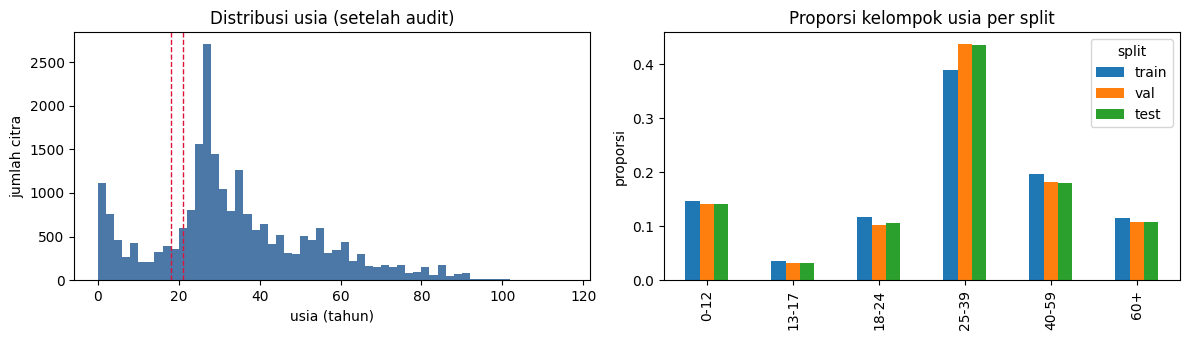

In [7]:
# @cell: audit_report
# Ringkasan manifest: jumlah citra per kelompok usia dan split, jenis kelamin, ras, dan ukuran citra.
split_counts = pd.crosstab(MANIFEST_DF.age_bin, MANIFEST_DF.split).reindex(AGE_BIN_LABELS)[['train', 'val', 'test']]
split_counts['total'] = split_counts.sum(axis=1)
split_counts.loc['total'] = split_counts.sum()
display(split_counts)
display(pd.DataFrame({'jenis kelamin': MANIFEST_DF.gender.map(GENDER_NAMES).value_counts()}).T)
display(pd.DataFrame({'ras': MANIFEST_DF.race.map(RACE_NAMES).value_counts()}).T)
image_sizes = MANIFEST_DF.width.astype(str) + 'x' + MANIFEST_DF.height.astype(str)
print('Ukuran citra terbanyak:', image_sizes.value_counts().head(3).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(MANIFEST_DF.age, bins=range(0, 118, 2), color='#4c78a8')
for L in CFG['L_LIST']:
    axes[0].axvline(L, color='crimson', ls='--', lw=1)   # garis batas usia age-gating
axes[0].set(title='Distribusi usia (setelah audit)', xlabel='usia (tahun)', ylabel='jumlah citra')
counts_by_bin = split_counts.drop('total').drop(columns='total')
(counts_by_bin / counts_by_bin.sum()).plot.bar(ax=axes[1])
axes[1].set(title='Proporsi kelompok usia per split', xlabel='', ylabel='proporsi')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'audit_distribusi.png', dpi=150); plt.show()

{'tinjau saja': 394722, 'digabung (satu split)': 6612}


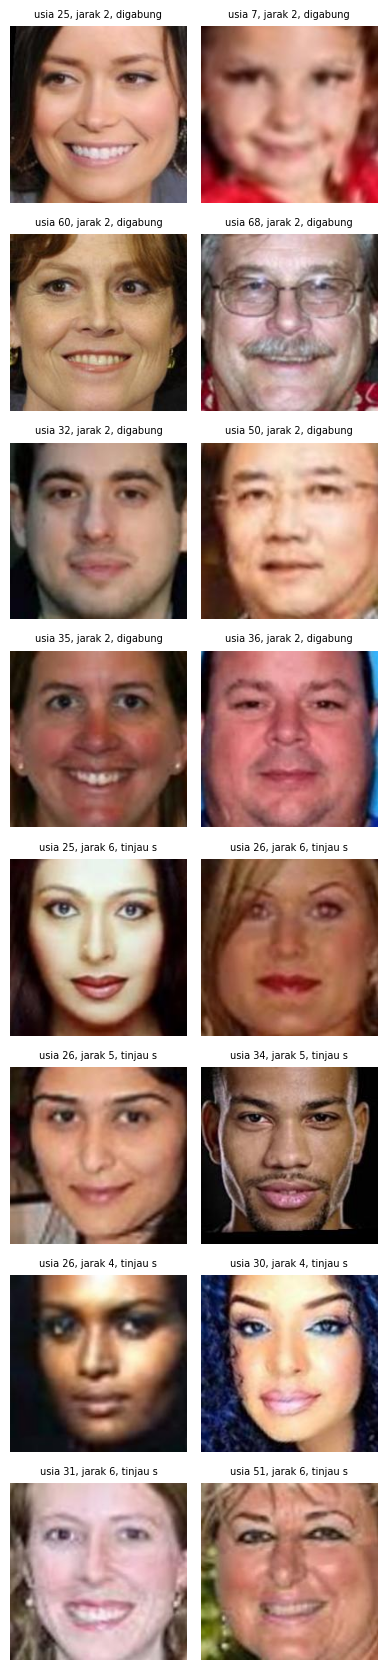

In [8]:
# @cell: near_review
# Contoh pasangan foto mirip. dHash hanya mengukur kemiripan visual, bukan identitas orang.
# Bila pasangan yang digabung ternyata orang berbeda, turunkan DHASH_MERGE_MAX, hapus manifest.csv, lalu jalankan ulang audit.
near_pairs_df = pd.read_csv(DIRS['manifest'] / 'near_pairs.csv')
print(near_pairs_df.action.value_counts().to_dict())
merged_pairs = near_pairs_df[near_pairs_df.action.str.startswith('digabung')]
review_pairs = near_pairs_df[near_pairs_df.action == 'tinjau saja']
pairs_to_show = pd.concat([merged_pairs.sample(min(4, len(merged_pairs)), random_state=0),
                           review_pairs.sample(min(4, len(review_pairs)), random_state=0)])
if len(pairs_to_show):
    fig, axes = plt.subplots(len(pairs_to_show), 2, figsize=(4, 2.1 * len(pairs_to_show)), squeeze=False)
    for row_idx, (_, pair) in enumerate(pairs_to_show.iterrows()):
        for col_idx, side in enumerate(['a', 'b']):
            ax = axes[row_idx, col_idx]
            ax.imshow(Image.open(LOCAL_DATA_DIR / pair[f'path_{side}']).convert('RGB'))
            ax.set_title(f"usia {pair[f'age_{side}']}, jarak {pair.dhash_dist}, {pair.action[:8]}", fontsize=7)
            ax.axis('off')
    plt.tight_layout(); plt.show()
else:
    print('Tidak ada pasangan mirip pada ambang tinjauan.')

## 3. Praproses, contoh data, dan uji awal model
- Semua model memakai praproses yang sama: sisi pendek diubah ke 256 piksel, dipotong tengah 224 x 224, lalu dinormalisasi dengan statistik ImageNet.
- Augmentasi hanya untuk data latih: rotasi sampai 10 derajat, geser sampai 5%, zoom 90 sampai 110%, pembalikan horizontal, serta perubahan ringan kecerahan, kontras, dan saturasi.
- Saat evaluasi dan inferensi, prediksi adalah rata-rata dari citra asli dan citra yang dicerminkan (`TTA_FLIP`).

Sel di bawah juga menampilkan contoh data per kelompok usia dan menjalankan model pralatih pada satu batch untuk memastikan alur data berjalan.

In [9]:
# @cell: data
# Transformasi citra, Dataset, DataLoader, dan pembagian train, val, test dari manifest.
NORMALIZE = T.Normalize(CFG['MEAN'], CFG['STD'])
EVAL_TRANSFORM = T.Compose([T.Resize(CFG['RESIZE']), T.CenterCrop(CFG['CROP']), T.ToTensor(), NORMALIZE])
TRAIN_TRANSFORM = T.Compose([
    T.Resize(CFG['RESIZE']),
    # Rotasi, geser, dan zoom acak. Area kosong diisi warna rata-rata ImageNet (bernilai 0 setelah normalisasi).
    T.RandomAffine(degrees=CFG['AUG_ROTATE'], translate=(CFG['AUG_TRANSLATE'],) * 2, scale=CFG['AUG_SCALE'],
                   fill=tuple(int(255 * v) for v in CFG['MEAN'])),
    T.CenterCrop(CFG['CROP']),
    T.RandomHorizontalFlip(),
    T.ColorJitter(brightness=CFG['JITTER'], contrast=CFG['JITTER'], saturation=CFG['JITTER']),
    T.ToTensor(), NORMALIZE])

class FaceAgeDataset(Dataset):
    """Pasangan (tensor citra, usia) dari baris-baris manifest."""
    def __init__(self, df, transform):
        self.paths = [LOCAL_DATA_DIR / p for p in df.path]
        self.ages = df.age.to_numpy(dtype=np.float32)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as image:
            tensor = self.transform(image.convert('RGB'))
        return tensor, self.ages[i]

def seed_worker(worker_id, base_seed):
    """Seed tiap worker DataLoader agar augmentasi acak bisa diulang."""
    np.random.seed(base_seed + worker_id)
    random.seed(base_seed + worker_id)

def make_loader(df, transform, shuffle, seed, sampler=None, batch_size=None):
    """DataLoader untuk df. shuffle hanya berlaku bila sampler tidak dipakai."""
    generator = torch.Generator()
    generator.manual_seed(seed)
    n_workers = CFG['NUM_WORKERS']
    return DataLoader(FaceAgeDataset(df, transform), batch_size=batch_size or CFG['BATCH_SIZE'],
                      shuffle=shuffle and sampler is None, sampler=sampler, num_workers=n_workers,
                      pin_memory=DEVICE.type == 'cuda', generator=generator, persistent_workers=n_workers > 0,
                      worker_init_fn=functools.partial(seed_worker, base_seed=seed) if n_workers else None)

TRAIN_DF = MANIFEST_DF[MANIFEST_DF.split == 'train'].reset_index(drop=True)
VAL_DF = MANIFEST_DF[MANIFEST_DF.split == 'val'].reset_index(drop=True)
_TEST_DF = MANIFEST_DF[MANIFEST_DF.split == 'test'].reset_index(drop=True)   # jangan dipakai langsung; ambil lewat get_split_df()
MEDIAN_AGE = float(np.median(TRAIN_DF.age))   # tebakan B0 dan nilai awal bias head
print(f'train {len(TRAIN_DF)} | val {len(VAL_DF)} | test {len(_TEST_DF)} (terkunci) | median usia latih = {MEDIAN_AGE}')

train 16176 | val 3468 | test 3466 (terkunci) | median usia latih = 29.0


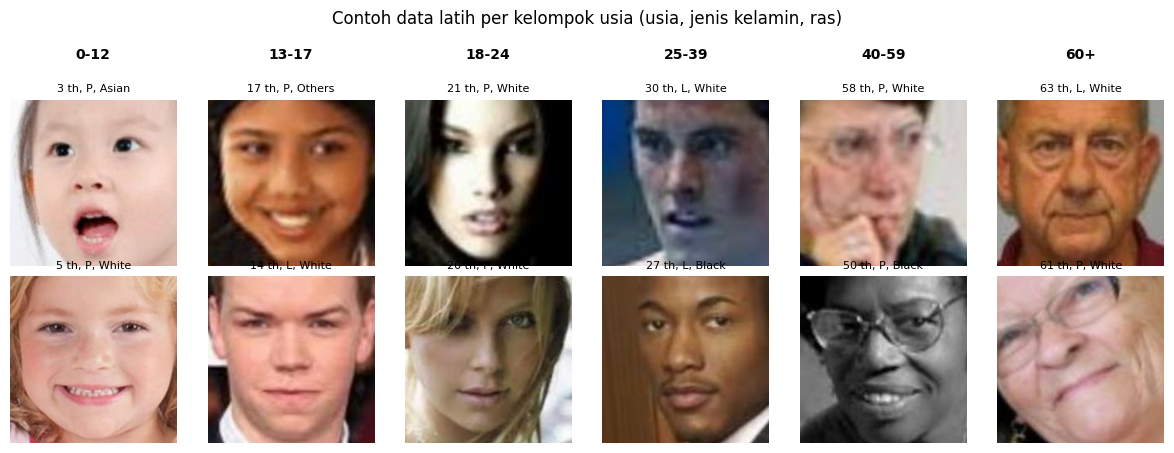

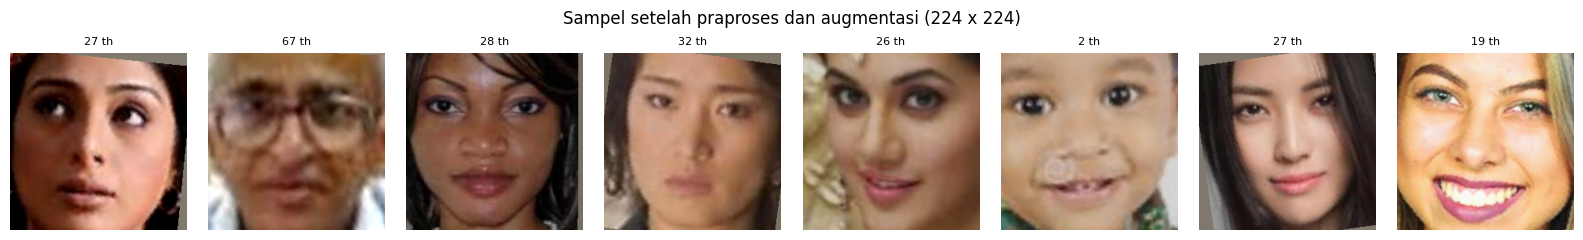

In [10]:
# @cell: examples
# Contoh citra latih per kelompok usia, lalu contoh hasil augmentasi.
fig, axes = plt.subplots(2, len(AGE_BIN_LABELS), figsize=(2 * len(AGE_BIN_LABELS), 4.4))
for col, bin_label in enumerate(AGE_BIN_LABELS):
    in_bin = TRAIN_DF[TRAIN_DF.age_bin == bin_label]
    samples = in_bin.sample(min(2, len(in_bin)), random_state=col)
    for row in range(2):
        ax = axes[row, col]
        ax.axis('off')
        if len(samples) > row:
            sample = samples.iloc[row]
            ax.imshow(Image.open(LOCAL_DATA_DIR / sample.path).convert('RGB'))
            ax.set_title(f"{sample.age} th, {GENDER_NAMES[sample.gender][0].upper()}, {RACE_NAMES[sample.race]}", fontsize=8)
    axes[0, col].text(0.5, 1.25, bin_label, transform=axes[0, col].transAxes, ha='center', fontsize=10, weight='bold')
plt.suptitle('Contoh data latih per kelompok usia (usia, jenis kelamin, ras)', y=1.02)
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'contoh_data.png', dpi=150, bbox_inches='tight'); plt.show()

# Cek augmentasi: wajah harus tetap terlihat utuh setelah resize, crop, dan augmentasi
aug_images, aug_ages = next(iter(make_loader(TRAIN_DF, TRAIN_TRANSFORM, True, 0, batch_size=8)))
std = torch.tensor(CFG['STD']).view(1, 3, 1, 1)
mean = torch.tensor(CFG['MEAN']).view(1, 3, 1, 1)
aug_images_display = (aug_images * std + mean).clamp(0, 1)   # balikkan normalisasi agar bisa ditampilkan
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(aug_images_display[i].permute(1, 2, 0))
    ax.set_title(f'{int(aug_ages[i])} th', fontsize=8)
    ax.axis('off')
plt.suptitle('Sampel setelah praproses dan augmentasi (224 x 224)'); plt.tight_layout()
plt.savefig(DIRS['figures'] / 'praproses_latih.png', dpi=150); plt.show()

## 4. Model dan prosedur pelatihan
- **Arsitektur:** MobileNetV3-Small pralatih ImageNet (torchvision). Lapisan terakhir `classifier[3]` diganti `Linear(1024, 1)` yang mengeluarkan usia dalam tahun. Bobot awalnya kecil dan biasnya sama dengan median usia latih, sehingga tebakan awal sama dengan B0. Dropout 0.3, tanpa softmax.
- **B1:** hanya `classifier` (head) yang dilatih. Backbone dan statistik BatchNorm beku.
- **M1:** mulai dari checkpoint B1 terbaik. Seluruh backbone (`UNFREEZE_LAST = 13`) dan head dilatih, dengan LR backbone 1e-4 dan LR head 3e-4. Statistik BatchNorm backbone ikut diperbarui (`M1_UPDATE_BN_STATS = True`).
- **B1 control:** mulai dari checkpoint B1 yang sama. Hanya head yang dilanjutkan, dengan pengaturan dan seed yang sama seperti M1.
- **Pelatihan:** loss Smooth L1 (beta 1), AdamW (weight decay 0.05, kecuali bias dan BatchNorm), batch 128. LR naik bertahap selama 2 epoch, lalu turun mengikuti kurva cosine. Maksimum 60 epoch, berhenti lebih awal bila MAE validasi tidak membaik selama 10 epoch. Checkpoint yang disimpan adalah epoch dengan MAE validasi terendah.

In [11]:
# @cell: model
# Definisi model, pengaturan parameter yang dilatih, dan fungsi prediksi.
def build_model(median_age, pretrained=True):
    """MobileNetV3-Small dengan head regresi satu output: usia dalam tahun."""
    weights = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
    model = models.mobilenet_v3_small(weights=weights, progress=False)
    age_head = nn.Linear(model.classifier[3].in_features, 1)
    nn.init.normal_(age_head.weight, 0.0, 0.01)
    nn.init.constant_(age_head.bias, median_age)   # tebakan awal = median usia latih
    model.classifier[3] = age_head
    model.classifier[2].p = CFG['DROPOUT']
    return model

def param_groups_with_decay(params, lr):
    """Dua grup AdamW: bobot (dimensi 2 ke atas) dengan weight decay, bias dan BatchNorm tanpa weight decay."""
    return [{'params': [p for p in params if p.ndim > 1], 'lr': lr, 'weight_decay': CFG['WEIGHT_DECAY']},
            {'params': [p for p in params if p.ndim <= 1], 'lr': lr, 'weight_decay': 0.0}]

def set_trainable_params(model, mode):
    """Bekukan semua parameter, lalu buka yang dilatih. Mengembalikan param group untuk AdamW.
    mode 'head': hanya head (B1, B1 control). mode 'finetune': head dan backbone (M1)."""
    for param in model.parameters():
        param.requires_grad = False
    head_params = list(model.classifier.parameters())
    for param in head_params:
        param.requires_grad = True
    param_groups = param_groups_with_decay(head_params, CFG['LR_HEAD'])
    if mode == 'finetune':
        backbone_params = [p for module in model.features[-CFG['UNFREEZE_LAST']:] for p in module.parameters()]
        for param in backbone_params:
            param.requires_grad = True
        param_groups += param_groups_with_decay(backbone_params, CFG['LR_BACKBONE'])
    return param_groups

def set_train_mode(model, mode):
    """Mode latih: dropout di head aktif. BatchNorm backbone tetap memakai statistik pralatih,
    kecuali pada M1 bila M1_UPDATE_BN_STATS aktif."""
    model.eval()
    model.classifier.train()
    if mode == 'finetune' and CFG['M1_UPDATE_BN_STATS']:
        for module in model.features[-CFG['UNFREEZE_LAST']:]:
            module.train()

def set_seed(seed):
    """Seed semua sumber acak dan buat operasi cuDNN deterministik."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def predict_batch(model, images):
    """Prediksi usia (tahun) untuk satu batch tensor. Bila TTA_FLIP aktif, hasilnya dirata-rata dengan citra yang dicerminkan."""
    preds = model(images).squeeze(1)
    if CFG['TTA_FLIP']:
        preds = (preds + model(torch.flip(images, dims=[3])).squeeze(1)) / 2
    return preds

@torch.inference_mode()
def predict_ages(model, df):
    """Prediksi usia untuk semua baris df tanpa augmentasi. Hasil berupa array numpy."""
    model.eval().to(DEVICE)
    batch_preds = []
    for images, _ in make_loader(df, EVAL_TRANSFORM, False, 0, batch_size=128):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=CFG['AMP'] and DEVICE.type == 'cuda'):
            batch_preds.append(predict_batch(model, images.to(DEVICE, non_blocking=True)).float().cpu())
    return torch.cat(batch_preds).numpy().astype(np.float64)

# Uji awal: model pralatih dengan head baru harus menebak dekat median usia pada satu batch validasi
sanity_model = build_model(MEDIAN_AGE).to(DEVICE).eval()
sanity_images, sanity_ages = next(iter(make_loader(VAL_DF, EVAL_TRANSFORM, False, 0, batch_size=16)))
with torch.inference_mode():
    sanity_preds = sanity_model(sanity_images.to(DEVICE)).squeeze(1).cpu()
print('keluaran awal (seharusnya dekat median):', sanity_preds[:6].numpy().round(2), '| label:', sanity_ages[:6].numpy())
print(f"MAE validasi B0 (median {MEDIAN_AGE}): {np.mean(np.abs(VAL_DF.age - MEDIAN_AGE)):.2f} tahun")
del sanity_model

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
keluaran awal (seharusnya dekat median): [28.99 28.86 28.97 28.94 28.87 29.14] | label: [100. 101. 105. 105.  10.  10.]
MAE validasi B0 (median 29.0): 14.41 tahun


In [12]:
# @cell: train_fn
# Fungsi pelatihan satu run. Hasil tiap run disimpan di folder runs/<metode>_s<seed>_<RUN_TAG> di Drive.
def get_run_dir(method, seed):
    return DIRS['runs'] / f"{method}_s{seed}_{CFG['RUN_TAG']}"

def lr_multiplier(step, warmup_steps, total_steps):
    """Pengali LR per langkah: naik linear selama warmup, lalu turun cosine sampai 1% di akhir pelatihan."""
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * min(1.0, progress)))

def train_run(method, seed, mode, init_checkpoint=None, sampler_weights=None):
    """Latih satu model dan simpan best.pt (checkpoint terbaik), history.csv (riwayat per epoch),
    config.json (pengaturan), dan done.json (ringkasan). Run yang sudah selesai dipakai ulang.

    method: nama run (B1, M1, B1c, M1bal). mode: 'head' atau 'finetune'.
    init_checkpoint: checkpoint awal; M1 dan B1 control mulai dari B1 terbaik.
    sampler_weights: bobot sampling per citra latih (opsional, untuk M1bal)."""
    run_dir = get_run_dir(method, seed)
    if init_checkpoint is not None and not (Path(init_checkpoint).parent / 'done.json').exists():
        raise RuntimeError(f'[{run_dir.name}] checkpoint awal {init_checkpoint} berasal dari run yang belum selesai.')
    if (run_dir / 'done.json').exists():
        trained_manifest_sha = json.load(open(run_dir / 'config.json')).get('manifest_sha256')
        if trained_manifest_sha != MANIFEST_SHA:
            raise RuntimeError(f'[{run_dir.name}] dilatih dengan manifest lain ({str(trained_manifest_sha)[:12]}...). '
                               f'Ganti CFG["RUN_TAG"] agar semua model dilatih ulang pada manifest sekarang.')
        print(f'[{run_dir.name}] sudah selesai, dipakai ulang:', json.load(open(run_dir / 'done.json')))
        return run_dir
    if run_dir.exists() and any(run_dir.iterdir()):
        # Run sebelumnya terputus (tidak ada done.json): arsipkan foldernya, lalu latih ulang dari awal
        archive_dir = run_dir.with_name(f"{run_dir.name}_terputus_{now_utc().replace(':', '')}")
        shutil.move(str(run_dir), str(archive_dir))
        print(f'[{run_dir.name}] run sebelumnya terputus, dipindah ke {archive_dir.name}; dilatih ulang dari awal')
    run_dir.mkdir(parents=True, exist_ok=True)

    set_seed(seed)
    model = build_model(MEDIAN_AGE)
    if init_checkpoint is not None:
        model.load_state_dict(torch.load(init_checkpoint, map_location='cpu')['model'])
    param_groups = set_trainable_params(model, mode)
    model.to(DEVICE)
    optimizer = torch.optim.AdamW(param_groups, weight_decay=CFG['WEIGHT_DECAY'])
    loss_fn = nn.SmoothL1Loss(beta=CFG['SMOOTH_L1_BETA'])
    use_amp = CFG['AMP'] and DEVICE.type == 'cuda'
    grad_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    sampler = None
    if sampler_weights is not None:
        sampler_generator = torch.Generator()
        sampler_generator.manual_seed(seed)
        sampler = WeightedRandomSampler(torch.as_tensor(sampler_weights, dtype=torch.double),
                                        num_samples=len(sampler_weights), replacement=True, generator=sampler_generator)
    train_loader = make_loader(TRAIN_DF, TRAIN_TRANSFORM, True, seed, sampler)
    total_steps = CFG['MAX_EPOCHS'] * len(train_loader)
    warmup_steps = max(1, CFG['WARMUP_EPOCHS'] * len(train_loader))
    lr_scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: lr_multiplier(step, warmup_steps, total_steps))

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    json.dump({'method': method, 'seed': seed, 'mode': mode,
               'init_ckpt': str(init_checkpoint) if init_checkpoint else None,
               'trainable_params': n_trainable, 'median_age': MEDIAN_AGE, 'manifest_sha256': MANIFEST_SHA,
               'started_utc': now_utc(), 'env': ENV_INFO,
               'cfg': {k: CFG[k] for k in ['BATCH_SIZE', 'LR_HEAD', 'LR_BACKBONE', 'WEIGHT_DECAY', 'SMOOTH_L1_BETA',
                                           'MAX_EPOCHS', 'PATIENCE', 'WARMUP_EPOCHS', 'UNFREEZE_LAST',
                                           'M1_UPDATE_BN_STATS', 'AMP', 'NUM_WORKERS',
                                           'JITTER', 'AUG_ROTATE', 'AUG_TRANSLATE', 'AUG_SCALE', 'TTA_FLIP',
                                           'DROPOUT', 'RESIZE', 'CROP']},
               'balanced_sampling': sampler is not None}, open(run_dir / 'config.json', 'w'), indent=1)
    print(f'[{run_dir.name}] parameter dilatih: {n_trainable:,}')

    best_val_mae, best_epoch, epochs_without_improvement, history = float('inf'), 0, 0, []
    train_start = time.time()
    for epoch in range(1, CFG['MAX_EPOCHS'] + 1):
        epoch_start = time.time()
        set_train_mode(model, mode)
        loss_sum = abs_error_sum = 0.0
        n_seen = 0
        for images, ages in train_loader:
            images, ages = images.to(DEVICE, non_blocking=True), ages.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=use_amp):
                preds = model(images).squeeze(1)
            loss = loss_fn(preds.float(), ages)
            optimizer.zero_grad(set_to_none=True)
            grad_scaler.scale(loss).backward()
            grad_scaler.step(optimizer)
            grad_scaler.update()
            lr_scheduler.step()
            loss_sum += loss.item() * len(ages)
            abs_error_sum += (preds.float() - ages).abs().sum().item()
            n_seen += len(ages)
        val_mae = float(np.mean(np.abs(predict_ages(model, VAL_DF) - VAL_DF.age.to_numpy())))
        history.append({'epoch': epoch, 'train_loss': loss_sum / n_seen, 'train_mae': abs_error_sum / n_seen,
                        'val_mae': val_mae, 'seconds': round(time.time() - epoch_start, 1)})
        pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
        saved_note = ''
        if val_mae < best_val_mae:
            best_val_mae, best_epoch, epochs_without_improvement = val_mae, epoch, 0
            saved_note = '  (checkpoint disimpan)'
            torch.save({'model': model.state_dict(), 'epoch': epoch, 'val_mae': val_mae, 'method': method,
                        'seed': seed, 'median_age': MEDIAN_AGE}, run_dir / 'best.pt')
        else:
            epochs_without_improvement += 1
        print(f'[{run_dir.name}] epoch {epoch:2d} | loss {loss_sum / n_seen:.3f} | MAE latih {abs_error_sum / n_seen:.2f} '
              f'| MAE val {val_mae:.2f} | {history[-1]["seconds"]} s{saved_note}')
        if epochs_without_improvement >= CFG['PATIENCE']:
            print(f'[{run_dir.name}] early stopping pada epoch {epoch}')
            break
    done_info = {'best_val_mae': best_val_mae, 'best_epoch': best_epoch, 'epochs_run': epoch,
                 'train_minutes': round((time.time() - train_start) / 60, 1), 'finished_utc': now_utc()}
    json.dump(done_info, open(run_dir / 'done.json', 'w'), indent=1)
    return run_dir

## 5. Pelatihan B1, M1, dan B1 control
Urutan per seed: B1 dilatih lebih dulu, lalu M1 dan B1 control sama-sama mulai dari checkpoint B1 terbaik. Perkiraan waktu: A100 sekitar 10 sampai 20 detik per epoch, T4 sekitar 40 sampai 80 detik per epoch (dibatasi jumlah vCPU untuk membaca citra). Bila `SEEDS` berisi tiga seed, seluruh rangkaian diulang per seed.

In [13]:
# @cell: train
# Jalankan semua run. RUN_DIRS menyimpan folder hasil untuk tiap pasangan (metode, seed).
RUN_DIRS = {}
for seed in CFG['SEEDS']:
    b1_dir = train_run('B1', seed, 'head')
    RUN_DIRS[('B1', seed)] = b1_dir
    RUN_DIRS[('M1', seed)] = train_run('M1', seed, 'finetune', init_checkpoint=b1_dir / 'best.pt')
    RUN_DIRS[('B1c', seed)] = train_run('B1c', seed, 'head', init_checkpoint=b1_dir / 'best.pt')
    if CFG['RUN_BALANCED_SAMPLING']:
        # Bobot tiap citra = 1 / jumlah citra di kelompok usianya, sehingga semua kelompok usia terambil sama sering
        balanced_weights = 1.0 / TRAIN_DF.age_bin.map(TRAIN_DF.age_bin.value_counts()).to_numpy()
        RUN_DIRS[('M1bal', seed)] = train_run('M1bal', seed, 'finetune', init_checkpoint=b1_dir / 'best.pt',
                                              sampler_weights=balanced_weights)

[B1_s43_r4] parameter dilatih: 591,873
[B1_s43_r4] epoch  1 | loss 14.536 | MAE latih 15.03 | MAE val 13.74 | 19.9 s  (checkpoint disimpan)
[B1_s43_r4] epoch  2 | loss 11.707 | MAE latih 12.20 | MAE val 10.60 | 17.1 s  (checkpoint disimpan)
[B1_s43_r4] epoch  3 | loss 9.687 | MAE latih 10.18 | MAE val 9.87 | 17.0 s  (checkpoint disimpan)
[B1_s43_r4] epoch  4 | loss 9.164 | MAE latih 9.65 | MAE val 9.46 | 16.3 s  (checkpoint disimpan)
[B1_s43_r4] epoch  5 | loss 8.907 | MAE latih 9.39 | MAE val 9.15 | 17.1 s  (checkpoint disimpan)
[B1_s43_r4] epoch  6 | loss 8.654 | MAE latih 9.14 | MAE val 8.93 | 16.5 s  (checkpoint disimpan)
[B1_s43_r4] epoch  7 | loss 8.439 | MAE latih 8.93 | MAE val 8.75 | 16.3 s  (checkpoint disimpan)
[B1_s43_r4] epoch  8 | loss 8.344 | MAE latih 8.83 | MAE val 8.57 | 16.6 s  (checkpoint disimpan)
[B1_s43_r4] epoch  9 | loss 8.230 | MAE latih 8.72 | MAE val 8.46 | 16.6 s  (checkpoint disimpan)
[B1_s43_r4] epoch 10 | loss 8.135 | MAE latih 8.62 | MAE val 8.35 | 16.6

/tmp/ipykernel_619/973597563.py:87: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  lr_scheduler.step()


[M1_s43_r4] epoch  1 | loss 11.874 | MAE latih 12.36 | MAE val 9.20 | 20.5 s  (checkpoint disimpan)
[M1_s43_r4] epoch  2 | loss 8.337 | MAE latih 8.82 | MAE val 7.68 | 17.6 s  (checkpoint disimpan)
[M1_s43_r4] epoch  3 | loss 7.113 | MAE latih 7.60 | MAE val 7.15 | 17.0 s  (checkpoint disimpan)
[M1_s43_r4] epoch  4 | loss 6.485 | MAE latih 6.97 | MAE val 6.66 | 16.9 s  (checkpoint disimpan)
[M1_s43_r4] epoch  5 | loss 6.069 | MAE latih 6.55 | MAE val 6.51 | 17.1 s  (checkpoint disimpan)
[M1_s43_r4] epoch  6 | loss 5.739 | MAE latih 6.22 | MAE val 6.19 | 17.4 s  (checkpoint disimpan)
[M1_s43_r4] epoch  7 | loss 5.585 | MAE latih 6.06 | MAE val 5.99 | 17.5 s  (checkpoint disimpan)
[M1_s43_r4] epoch  8 | loss 5.432 | MAE latih 5.91 | MAE val 5.82 | 17.2 s  (checkpoint disimpan)
[M1_s43_r4] epoch  9 | loss 5.236 | MAE latih 5.71 | MAE val 6.06 | 16.7 s
[M1_s43_r4] epoch 10 | loss 5.086 | MAE latih 5.56 | MAE val 5.62 | 16.8 s  (checkpoint disimpan)
[M1_s43_r4] epoch 11 | loss 4.958 | MAE l

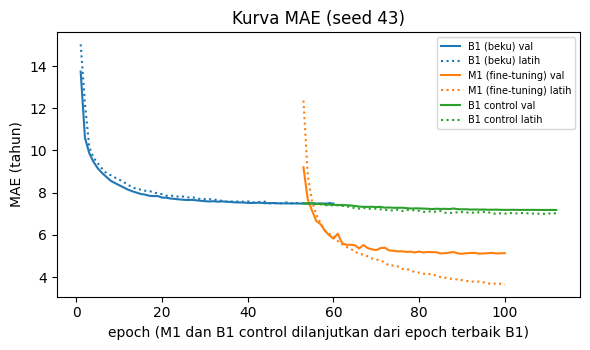

,best_val_mae,best_epoch,epochs_run,train_minutes,finished_utc
B1_s43,7.484,52,60,16.7,2026-11-02T16:38:54+00:00
M1_s43,5.105,38,48,13.7,2026-11-02T16:52:34+00:00
B1c_s43,7.181,60,60,16.5,2026-11-02T17:09:02+00:00


In [14]:
# @cell: curves
# Kurva MAE latih dan validasi per epoch, lalu ringkasan tiap run (epoch terbaik dan lama latih).
fig, axes = plt.subplots(1, len(CFG['SEEDS']), figsize=(6 * len(CFG['SEEDS']), 3.6), squeeze=False)
for col, seed in enumerate(CFG['SEEDS']):
    ax = axes[0, col]
    for (method, run_seed), run_dir in RUN_DIRS.items():
        if run_seed != seed:
            continue
        history = pd.read_csv(run_dir / 'history.csv')
        # M1 dan B1 control dilanjutkan dari epoch terbaik B1, jadi sumbu epoch-nya digeser
        epoch_offset = 0 if method == 'B1' else int(json.load(open(RUN_DIRS[('B1', run_seed)] / 'done.json'))['best_epoch'])
        val_line, = ax.plot(history.epoch + epoch_offset, history.val_mae, label=f'{METHOD_NAMES[method]} val')
        ax.plot(history.epoch + epoch_offset, history.train_mae, ls=':', color=val_line.get_color(),
                label=f'{METHOD_NAMES[method]} latih')
    ax.set(title=f'Kurva MAE (seed {seed})', xlabel='epoch (M1 dan B1 control dilanjutkan dari epoch terbaik B1)',
           ylabel='MAE (tahun)')
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'kurva_mae.png', dpi=150); plt.show()
display(pd.DataFrame({f'{method}_s{run_seed}': json.load(open(run_dir / 'done.json'))
                      for (method, run_seed), run_dir in RUN_DIRS.items()}).T)

## 6. Evaluasi
Selama `TEST_UNLOCKED = False`, semua tabel dan grafik di bawah dihitung pada data validasi (`EVAL_SPLIT = 'val'`) untuk memilih konfigurasi dan ambang T. Setelah konfigurasi final ditetapkan, ubah ke `True` lalu jalankan ulang bagian 6 sampai 8; hasilnya kemudian dihitung pada data uji. Waktu pembukaan data uji dicatat di Drive.

Istilah age-gating (Challenge-T):
- L adalah batas usia, misalnya 18 tahun. Pengguna diterima bila prediksi usianya minimal T, dengan T >= L sebagai margin keamanan.
- FPR: proporsi pengguna di bawah L yang lolos (prediksi >= T). Harus kecil.
- FNR: proporsi pengguna dewasa (usia >= L) yang tertahan (prediksi < T).
- T rekomendasi: T terkecil dengan FPR validasi <= `FPR_TARGET`.

In [15]:
# @cell: unlock
# Pilih split evaluasi dan siapkan prediksi semua metode.
TEST_UNLOCKED = False   # ubah ke True hanya setelah konfigurasi dan T dipilih dari validasi

EVAL_SPLIT = 'test' if TEST_UNLOCKED else 'val'
if TEST_UNLOCKED:
    unlock_record_path = DIRS['results'] / 'test_unlock.json'   # bukti kapan data uji dibuka
    if not unlock_record_path.exists():
        json.dump({'unlocked_utc': now_utc(), 'manifest_sha256': MANIFEST_SHA,
                   'runs': [run_dir.name for run_dir in RUN_DIRS.values()]}, open(unlock_record_path, 'w'), indent=1)
    print('Data uji dibuka:', json.load(open(unlock_record_path)))

def get_split_df(split):
    """DataFrame satu split. Data uji hanya bisa diambil setelah TEST_UNLOCKED = True."""
    if split == 'test' and not TEST_UNLOCKED:
        raise PermissionError('Data uji masih dikunci. Pilih konfigurasi dengan validasi, lalu set TEST_UNLOCKED = True.')
    return {'train': TRAIN_DF, 'val': VAL_DF, 'test': _TEST_DF}[split]

def get_predictions(method, seed, split):
    """Prediksi mentah satu metode pada satu split (tanpa pembulatan). Disimpan sebagai CSV di Drive dan dipakai ulang."""
    df = get_split_df(split)
    cache_name = 'B0' if method == 'B0' else get_run_dir(method, seed).name
    cache_path = DIRS['results'] / 'preds' / f'{cache_name}_{split}_{MANIFEST_SHA[:8]}.csv'
    if cache_path.exists():
        return pd.read_csv(cache_path).pred.to_numpy()
    if method == 'B0':
        preds = np.full(len(df), MEDIAN_AGE)
    else:
        checkpoint = torch.load(get_run_dir(method, seed) / 'best.pt', map_location='cpu')
        model = build_model(checkpoint['median_age'], pretrained=False)
        model.load_state_dict(checkpoint['model'])
        preds = predict_ages(model, df)
    pd.DataFrame({'path': df.path, 'age': df.age, 'pred': preds}).to_csv(cache_path, index=False)
    return preds

METHODS = ['B0', 'B1', 'M1', 'B1c'] + (['M1bal'] if CFG['RUN_BALANCED_SAMPLING'] else [])
EVAL_SEED = CFG['SEEDS'][0]   # seed yang dievaluasi di bagian ini; perbandingan antar seed ada di sel seeds
EVAL_DF = get_split_df(EVAL_SPLIT)
Y_TRUE = EVAL_DF.age.to_numpy().astype(float)
PREDICTIONS = {method: get_predictions(method, EVAL_SEED, EVAL_SPLIT) for method in METHODS}
print(f'Evaluasi pada split: {EVAL_SPLIT} (n = {len(EVAL_DF)}), seed {EVAL_SEED}')

Evaluasi pada split: val (n = 3468), seed 43


In [16]:
# @cell: metrics
# Fungsi metrik dan tabel galat usia tiap metode.
Z_SCORE = {0.90: 1.645, 0.95: 1.96, 0.99: 2.576}[CFG['CI']]   # nilai z sesuai tingkat kepercayaan CI

def regression_metrics(y_true, y_pred):
    """MAE, RMSE, median galat absolut, dan bias rata-rata (prediksi dikurangi label), dalam tahun."""
    error = y_pred - y_true
    return {'n': len(y_true), 'MAE': np.mean(np.abs(error)), 'RMSE': np.sqrt(np.mean(error ** 2)),
            'MedAE': np.median(np.abs(error)), 'bias (pred-label)': np.mean(error)}

def wilson_interval(successes, n):
    """Interval kepercayaan Wilson untuk proporsi successes / n."""
    if n == 0:
        return (np.nan, np.nan)
    p_hat = successes / n
    denominator = 1 + Z_SCORE ** 2 / n
    center = (p_hat + Z_SCORE ** 2 / (2 * n)) / denominator
    half_width = Z_SCORE * np.sqrt(p_hat * (1 - p_hat) / n + Z_SCORE ** 2 / (4 * n ** 2)) / denominator
    return (max(0.0, center - half_width), min(1.0, center + half_width))

def gating_rates(y_true, y_pred, L, threshold):
    """FPR dan FNR kebijakan age-gating dengan batas usia L: pengguna diterima bila prediksi >= threshold (T)."""
    is_minor, is_adult = y_true < L, y_true >= L
    false_accepts = int(((y_pred >= threshold) & is_minor).sum())
    false_rejects = int(((y_pred < threshold) & is_adult).sum())
    n_minor, n_adult = int(is_minor.sum()), int(is_adult.sum())
    return {'L': L, 'T': threshold, 'n<L': n_minor, 'n>=L': n_adult,
            'FPR': false_accepts / n_minor if n_minor else np.nan, 'FPR CI': wilson_interval(false_accepts, n_minor),
            'FNR': false_rejects / n_adult if n_adult else np.nan, 'FNR CI': wilson_interval(false_rejects, n_adult)}

def auc_minor_vs_adult(y_true, y_pred, L):
    """AUC prediksi usia dalam memisahkan pengguna dewasa (>= L) dari pengguna di bawah umur."""
    is_adult = (y_true >= L).astype(int)
    return roc_auc_score(is_adult, y_pred) if 0 < is_adult.sum() < len(is_adult) else np.nan

def recommend_threshold(method, L):
    """T terkecil dengan FPR validasi <= FPR_TARGET. Selalu dihitung dari validasi, juga saat data uji dibuka.
    Mengembalikan (T, target_tercapai). Bila target tidak tercapai, T = batas atas pencarian."""
    val_true, val_pred = VAL_DF.age.to_numpy().astype(float), get_predictions(method, EVAL_SEED, 'val')
    for threshold in range(L, L + CFG['T_SEARCH_MAX_OFFSET'] + 1):
        if gating_rates(val_true, val_pred, L, threshold)['FPR'] <= CFG['FPR_TARGET']:
            return threshold, True
    return L + CFG['T_SEARCH_MAX_OFFSET'], False

METRICS_SUMMARY = pd.DataFrame({METHOD_NAMES[m]: regression_metrics(Y_TRUE, PREDICTIONS[m]) for m in METHODS}).T
METRICS_SUMMARY['penurunan MAE vs B0'] = 1 - METRICS_SUMMARY.MAE / METRICS_SUMMARY.loc[METHOD_NAMES['B0'], 'MAE']
print(f'Galat usia pada {EVAL_SPLIT} (tahun)')
display(METRICS_SUMMARY)
METRICS_SUMMARY.to_csv(DIRS['results'] / f'ringkasan_{EVAL_SPLIT}.csv')

Galat usia pada val (tahun)


,n,MAE,RMSE,MedAE,bias (pred-label),penurunan MAE vs B0
B0 (median),3468.0,14.410,19.919,9.000,-4.014,0.000
B1 (beku),3468.0,7.484,10.371,5.312,-0.743,0.481
M1 (fine-tuning),3468.0,5.105,7.323,3.500,-0.416,0.646
B1 control,3468.0,7.181,10.063,4.969,-0.848,0.502


MAE per kelompok usia (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
age_bin,,,,,
0-12,487,24.774,6.702,2.328,5.972
13-17,112,13.607,9.885,5.509,9.070
18-24,353,7.221,5.681,4.206,5.460
25-39,1516,3.489,5.348,4.394,5.258
40-59,629,20.097,9.533,7.213,9.346
60+,371,42.873,14.751,8.815,14.020


MAE per jenis kelamin (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
gender,,,,,
laki-laki,1862,15.461,7.452,5.154,7.141
perempuan,1606,13.192,7.521,5.048,7.227


MAE per ras (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
race,,,,,
Asian,537,15.142,6.632,3.778,6.304
Black,685,9.342,7.230,5.422,7.086
Indian,589,13.299,7.234,4.883,6.898
Others,219,11.804,6.068,4.014,5.717
White,1438,17.403,8.240,5.706,7.892


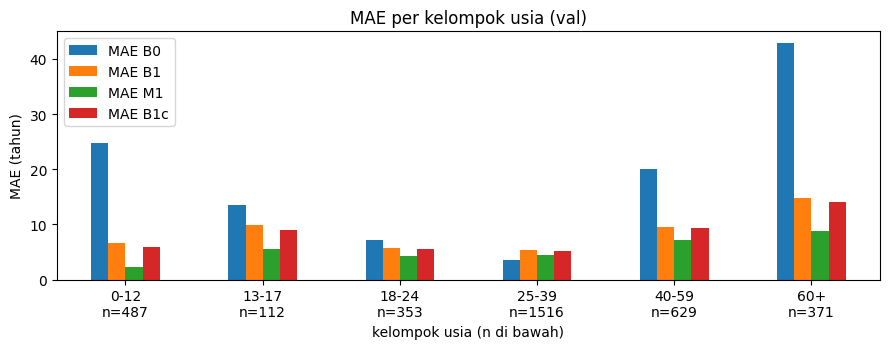

In [17]:
# @cell: groups
# MAE per kelompok usia, jenis kelamin, dan ras, untuk melihat kelompok mana yang paling sulit ditebak.
def mae_by_group(column, code_names=None, order=None):
    """Tabel MAE tiap metode per nilai kolom manifest. code_names mengubah kode angka menjadi nama."""
    rows = []
    group_values = EVAL_DF[column].map(code_names) if code_names else EVAL_DF[column]
    for group in (order or sorted(group_values.unique())):
        in_group = (group_values == group).to_numpy()
        row = {column: group, 'n': int(in_group.sum())}
        for method in METHODS:
            row[f'MAE {method}'] = (np.mean(np.abs(PREDICTIONS[method][in_group] - Y_TRUE[in_group]))
                                    if in_group.any() else np.nan)
        rows.append(row)
    return pd.DataFrame(rows).set_index(column)

MAE_BY_AGE = mae_by_group('age_bin', order=AGE_BIN_LABELS)
MAE_BY_GENDER = mae_by_group('gender', GENDER_NAMES)
MAE_BY_RACE = mae_by_group('race', RACE_NAMES)
for group_name, table in [('kelompok usia', MAE_BY_AGE), ('jenis kelamin', MAE_BY_GENDER), ('ras', MAE_BY_RACE)]:
    print(f'MAE per {group_name} ({EVAL_SPLIT})')
    display(table)
    table.to_csv(DIRS['results'] / f"mae_per_{group_name.replace(' ', '_')}_{EVAL_SPLIT}.csv")

ax = MAE_BY_AGE.drop(columns='n').plot.bar(figsize=(9, 3.6), rot=0)
ax.set(title=f'MAE per kelompok usia ({EVAL_SPLIT})', xlabel='kelompok usia (n di bawah)', ylabel='MAE (tahun)')
ax.set_xticklabels([f'{bin_label}\nn={n}' for bin_label, n in zip(MAE_BY_AGE.index, MAE_BY_AGE.n)])
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'mae_per_kelompok_{EVAL_SPLIT}.png', dpi=150); plt.show()

Challenge-T pada val. FPR: pengguna di bawah L yang lolos. FNR: pengguna dewasa yang tertahan. CI Wilson 95%. T rekomendasi: T terkecil dengan FPR validasi <= 0.05.


n<L  n>=L    FPR          FPR CI    FNR  \
metode           L  T                                             
B0 (median)      18 18  599  2869  1.000  [0.994, 1.000]  0.000   
                    21  599  2869  1.000  [0.994, 1.000]  0.000   
                    23  599  2869  1.000  [0.994, 1.000]  0.000   
                    30  599  2869  0.000  [0.000, 0.006]  1.000   
                 21 21  691  2777  1.000  [0.994, 1.000]  0.000   
                    24  691  2777  1.000  [0.994, 1.000]  0.000   
                    26  691  2777  1.000  [0.994, 1.000]  0.000   
                    30  691  2777  0.000  [0.000, 0.006]  1.000   
B1 (beku)        18 18  599  2869  0.311  [0.275, 0.349]  0.020   
                    21  599  2869  0.254  [0.221, 0.290]  0.043   
                    23  599  2869  0.210  [0.180, 0.245]  0.082   
                    31  599  2869  0.047  [0.033, 0.067]  0.451   
                 21 21  691  2777  0.320  [0.286, 0.356]  0.036   
                    24  691  2777  0.243  [0.213, 0.276]  0.107   
                    26  691  2777  0.169  [0.143, 0.199]  0.191   
                    32  691  2777  0.049  [0.035, 0.068]  0.475   
M1 (fine-tuning) 18 18  599  2869  0.147  [0.121, 0.178]  0.008   
                    21  599  2869  0.107  [0.085, 0.134]  0.023   
                    23  599  2869  0.070  [0.052, 0.093]  0.052   
                    25  599  2869  0.040  [0.027, 0.059]  0.147   
                 21 21  691  2777  0.197  [0.169, 0.228]  0.017   
                    24  691  2777  0.098  [0.078, 0.123]  0.072   
                    26  691  2777  0.049  [0.035, 0.068]  0.196   
B1 control       18 18  599  2869  0.287  [0.252, 0.325]  0.021   
                    21  599  2869  0.230  [0.198, 0.266]  0.042   
                    23  599  2869  0.185  [0.156, 0.218]  0.082   
                    30  599  2869  0.045  [0.031, 0.065]  0.428   
                 21 21  691  2777  0.302  [0.269, 0.338]  0.036   
                    24  691  2777  0.221  [0.192, 0.254]  0.108   
                    26  691  2777  0.146  [0.122, 0.174]  0.200   
                    31  691  2777  0.049  [0.035, 0.068]  0.452   

                                FNR CI    AUC T rekomendasi (val)  
metode           L  T                                              
B0 (median)      18 18  [0.000, 0.001]  0.500                      
                    21  [0.000, 0.001]  0.500                      
                    23  [0.000, 0.001]  0.500                      
                    30  [0.999, 1.000]  0.500                  ya  
                 21 21  [0.000, 0.001]  0.500                      
                    24  [0.000, 0.001]  0.500                      
                    26  [0.000, 0.001]  0.500                      
                    30  [0.999, 1.000]  0.500                  ya  
B1 (beku)        18 18  [0.016, 0.026]  0.928                      
                    21  [0.036, 0.051]  0.928                      
                    23  [0.073, 0.093]  0.928                      
                    31  [0.433, 0.469]  0.928                  ya  
                 21 21  [0.030, 0.044]  0.913                      
                    24  [0.096, 0.119]  0.913                      
                    26  [0.177, 0.206]  0.913                      
                    32  [0.456, 0.493]  0.913                  ya  
M1 (fine-tuning) 18 18  [0.005, 0.012]  0.983                      
                    21  [0.018, 0.029]  0.983                      
                    23  [0.044, 0.060]  0.983                      
                    25  [0.135, 0.161]  0.983                  ya  
                 21 21  [0.012, 0.022]  0.970                      
                    24  [0.063, 0.083]  0.970                      
                    26  [0.181, 0.211]  0.970                  ya  
B1 control       18 18  [0.016, 0.026]  0.937                      
                    21  [0.035, 0.050]  0.93

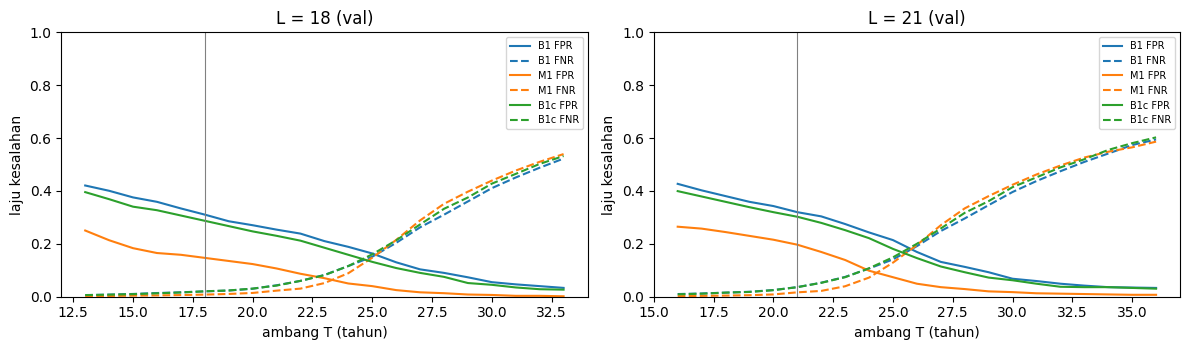

In [18]:
# @cell: gating
# Tabel FPR, FNR, dan AUC age-gating untuk tiap metode, batas usia L, dan beberapa ambang T.
def format_ci(ci):
    return f'[{ci[0]:.3f}, {ci[1]:.3f}]'

RECOMMENDED_T = {}   # kunci (metode, L), nilai T rekomendasi dari validasi
gating_rows = []
for method in METHODS:
    for L in CFG['L_LIST']:
        RECOMMENDED_T[(method, L)], target_met = recommend_threshold(method, L)
        thresholds = sorted(set([L + offset for offset in CFG['T_OFFSETS']] + [RECOMMENDED_T[(method, L)]]))
        for threshold in thresholds:
            row = gating_rates(Y_TRUE, PREDICTIONS[method], L, threshold)
            is_recommended = threshold == RECOMMENDED_T[(method, L)]
            recommended_note = ('ya' if target_met else 'ya, target FPR tidak tercapai') if is_recommended else ''
            row.update({'metode': METHOD_NAMES[method], 'AUC': auc_minor_vs_adult(Y_TRUE, PREDICTIONS[method], L),
                        'T rekomendasi (val)': recommended_note})
            gating_rows.append(row)
GATING_TABLE = pd.DataFrame(gating_rows).set_index(['metode', 'L', 'T'])
GATING_TABLE['FPR CI'] = GATING_TABLE['FPR CI'].map(format_ci)
GATING_TABLE['FNR CI'] = GATING_TABLE['FNR CI'].map(format_ci)
print(f"Challenge-T pada {EVAL_SPLIT}. FPR: pengguna di bawah L yang lolos. FNR: pengguna dewasa yang tertahan. "
      f"CI Wilson {int(CFG['CI'] * 100)}%. T rekomendasi: T terkecil dengan FPR validasi <= {CFG['FPR_TARGET']}.")
display(GATING_TABLE)
GATING_TABLE.to_csv(DIRS['results'] / f'challenge_T_{EVAL_SPLIT}.csv')

fig, axes = plt.subplots(1, len(CFG['L_LIST']), figsize=(6 * len(CFG['L_LIST']), 3.6), squeeze=False)
for col, L in enumerate(CFG['L_LIST']):
    ax = axes[0, col]
    threshold_grid = np.arange(L - 5, L + CFG['T_SEARCH_MAX_OFFSET'] + 1)
    for method in [m for m in METHODS if m != 'B0']:
        rates = [gating_rates(Y_TRUE, PREDICTIONS[method], L, t) for t in threshold_grid]
        fpr_line, = ax.plot(threshold_grid, [r['FPR'] for r in rates], label=f'{method} FPR')
        ax.plot(threshold_grid, [r['FNR'] for r in rates], ls='--', color=fpr_line.get_color(), label=f'{method} FNR')
    ax.axvline(L, color='grey', lw=0.8)
    ax.set(title=f'L = {L} ({EVAL_SPLIT})', xlabel='ambang T (tahun)', ylabel='laju kesalahan', ylim=(0, 1))
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'fpr_fnr_{EVAL_SPLIT}.png', dpi=150); plt.show()

In [19]:
# @cell: bootstrap
# Uji apakah selisih MAE antar metode nyata atau kebetulan, dengan bootstrap berpasangan pada citra yang sama.
def paired_bootstrap_mae(method_a, method_b, seed=0):
    """Selisih MAE (a dikurangi b) beserta CI. Negatif berarti a lebih akurat. Bila CI tidak memuat 0, selisihnya signifikan."""
    abs_error_a = np.abs(PREDICTIONS[method_a] - Y_TRUE)
    abs_error_b = np.abs(PREDICTIONS[method_b] - Y_TRUE)
    rng = np.random.default_rng(seed)
    resample_idx = rng.integers(0, len(Y_TRUE), size=(CFG['N_BOOT'], len(Y_TRUE)))
    mae_diffs = abs_error_a[resample_idx].mean(1) - abs_error_b[resample_idx].mean(1)
    ci_low, ci_high = np.percentile(mae_diffs, [(1 - CFG['CI']) / 2 * 100, (1 + CFG['CI']) / 2 * 100])
    return {'pasangan': f'{method_a} - {method_b}', 'selisih MAE': abs_error_a.mean() - abs_error_b.mean(),
            'CI bawah': ci_low, 'CI atas': ci_high, 'CI memuat 0': bool(ci_low <= 0 <= ci_high)}

comparison_pairs = [('M1', 'B0'), ('M1', 'B1'), ('M1', 'B1c'), ('B1c', 'B1'), ('B1', 'B0')]
if 'M1bal' in METHODS:
    comparison_pairs.append(('M1bal', 'M1'))
BOOTSTRAP_TABLE = pd.DataFrame([paired_bootstrap_mae(a, b) for a, b in comparison_pairs]).set_index('pasangan')
print(f"Bootstrap berpasangan ({CFG['N_BOOT']} pengambilan ulang, CI {int(CFG['CI'] * 100)}%) pada {EVAL_SPLIT}")
display(BOOTSTRAP_TABLE)
BOOTSTRAP_TABLE.to_csv(DIRS['results'] / f'bootstrap_{EVAL_SPLIT}.csv')

Bootstrap berpasangan (1000 pengambilan ulang, CI 95%) pada val


,selisih MAE,CI bawah,CI atas,CI memuat 0
pasangan,,,,
M1 - B0,-9.305,-9.735,-8.868,False
M1 - B1,-2.379,-2.584,-2.164,False
M1 - B1c,-2.076,-2.265,-1.875,False
B1c - B1,-0.303,-0.353,-0.257,False
B1 - B0,-6.926,-7.353,-6.521,False


In [20]:
# @cell: seeds
# Bila lebih dari satu seed dilatih: rata-rata dan simpangan baku MAE antar seed.
if len(CFG['SEEDS']) > 1:
    rows = []
    for method in [m for m in METHODS if m != 'B0']:
        mae_per_seed = [np.mean(np.abs(get_predictions(method, seed, EVAL_SPLIT) - Y_TRUE)) for seed in CFG['SEEDS']]
        rows.append({'metode': METHOD_NAMES[method], 'MAE rerata': np.mean(mae_per_seed),
                     'SD': np.std(mae_per_seed, ddof=1), 'per seed': np.round(mae_per_seed, 3).tolist()})
    SEED_TABLE = pd.DataFrame(rows).set_index('metode')
    display(SEED_TABLE)
    SEED_TABLE.to_csv(DIRS['results'] / f'antar_seed_{EVAL_SPLIT}.csv')
else:
    print('Satu seed: keterbatasan ini dinyatakan dalam laporan.')

Satu seed: keterbatasan ini dinyatakan dalam laporan.


## 7. Analisis galat
Grafik prediksi terhadap label, histogram residual (prediksi dikurangi label), dan 12 citra dengan galat tertinggi pada M1. Pengamatan visual dicatat sebagai dugaan penyebab, bukan bukti.

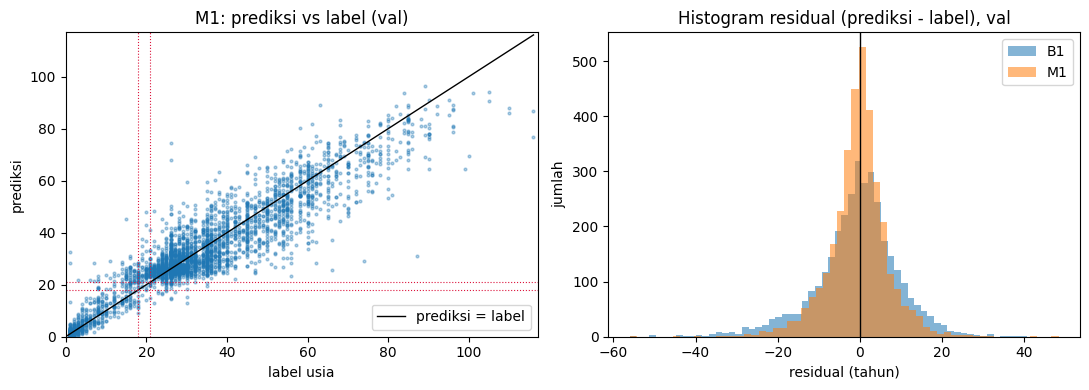

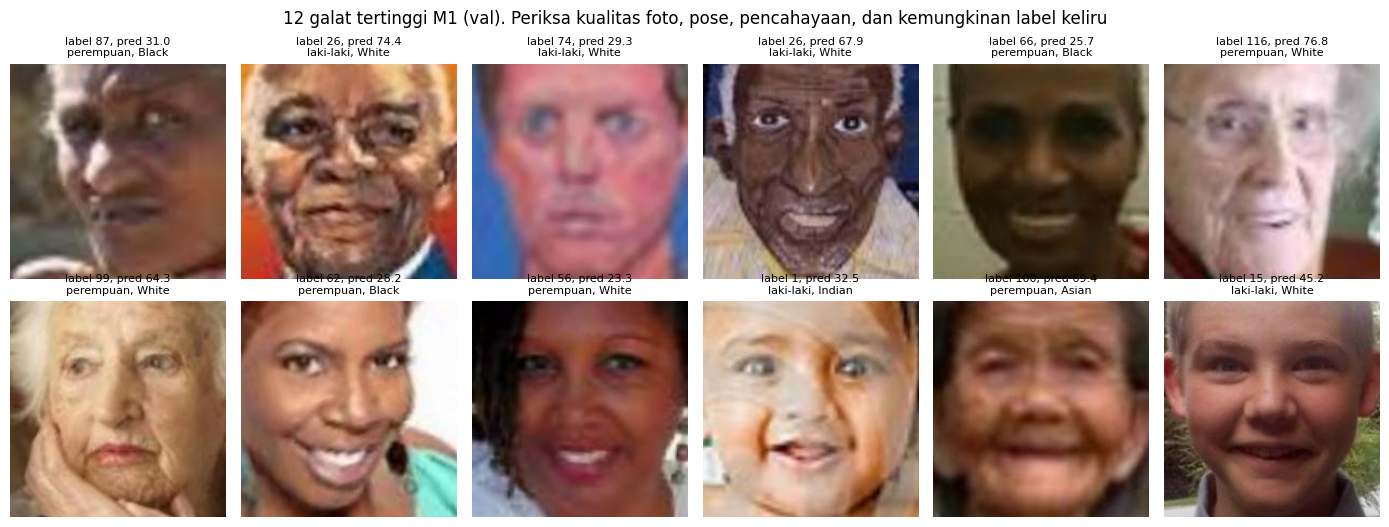

In [21]:
# @cell: errors
# Pola kesalahan M1: sebaran prediksi, residual, dan citra dengan galat terbesar.
m1_preds = PREDICTIONS['M1']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Y_TRUE, m1_preds, s=4, alpha=0.35)
axes[0].plot([0, 116], [0, 116], color='k', lw=1, label='prediksi = label')
for L in CFG['L_LIST']:
    axes[0].axvline(L, color='crimson', ls=':', lw=0.8)
    axes[0].axhline(L, color='crimson', ls=':', lw=0.8)
axes[0].set(title=f'M1: prediksi vs label ({EVAL_SPLIT})', xlabel='label usia', ylabel='prediksi',
            xlim=(0, 117), ylim=(0, 117))
axes[0].legend()
for method in ['B1', 'M1']:
    axes[1].hist(PREDICTIONS[method] - Y_TRUE, bins=60, alpha=0.55, label=method)
axes[1].axvline(0, color='k', lw=1)
axes[1].set(title=f'Histogram residual (prediksi - label), {EVAL_SPLIT}', xlabel='residual (tahun)', ylabel='jumlah')
axes[1].legend(); plt.tight_layout()
plt.savefig(DIRS['figures'] / f'prediksi_residual_{EVAL_SPLIT}.png', dpi=150); plt.show()

error_df = pd.DataFrame({'path': EVAL_DF.path, 'age': EVAL_DF.age, 'gender': EVAL_DF.gender.map(GENDER_NAMES),
                         'race': EVAL_DF.race.map(RACE_NAMES), 'pred': m1_preds,
                         'abs_err': np.abs(m1_preds - Y_TRUE)}).sort_values('abs_err', ascending=False)
error_df.head(50).to_csv(DIRS['results'] / f'galat_tertinggi_M1_{EVAL_SPLIT}.csv', index=False)
worst_cases = error_df.head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
for ax, (_, case) in zip(axes.ravel(), worst_cases.iterrows()):
    ax.imshow(Image.open(LOCAL_DATA_DIR / case.path).convert('RGB'))
    ax.axis('off')
    ax.set_title(f'label {case.age}, pred {case.pred:.1f}\n{case.gender}, {case.race}', fontsize=8)
plt.suptitle(f'12 galat tertinggi M1 ({EVAL_SPLIT}). Periksa kualitas foto, pose, pencahayaan, dan kemungkinan label keliru')
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'galat_tertinggi_{EVAL_SPLIT}.png', dpi=150); plt.show()

## 8. Biaya komputasi
Jumlah parameter, MAdds (dihitung dengan hook pada Conv2d dan Linear), ukuran berkas, dan latensi CPU untuk satu citra setelah pemanasan (median dan persentil ke-95). Waktu praproses dan inferensi diukur terpisah. Inferensi diukur sama seperti saat evaluasi, termasuk TTA flip bila aktif. Latensi CPU Colab hanya perkiraan untuk perangkat edge.

In [22]:
# @cell: efficiency
# Ukur biaya model M1: parameter, MAdds, ukuran berkas, dan latensi CPU.
def count_macs(model, input_size=224):
    """Jumlah operasi multiply-accumulate untuk satu citra, dari lapisan Conv2d dan Linear."""
    macs = 0
    def count_conv(module, inputs, output):
        nonlocal macs
        macs += output[0].numel() * (module.in_channels // module.groups) * module.kernel_size[0] * module.kernel_size[1]
    def count_linear(module, inputs, output):
        nonlocal macs
        macs += module.in_features * module.out_features
    hooks = [m.register_forward_hook(count_conv) for m in model.modules() if isinstance(m, nn.Conv2d)]
    hooks += [m.register_forward_hook(count_linear) for m in model.modules() if isinstance(m, nn.Linear)]
    model.eval()
    with torch.inference_mode():
        model(torch.zeros(1, 3, input_size, input_size))
    for hook in hooks:
        hook.remove()
    return macs

def model_file_size_mb(model):
    """Ukuran state_dict model bila disimpan sebagai berkas FP32."""
    tmp_path = Path('/tmp/_size.pt')
    torch.save(model.state_dict(), tmp_path)
    return tmp_path.stat().st_size / 1e6

m1_checkpoint = torch.load(get_run_dir('M1', EVAL_SEED) / 'best.pt', map_location='cpu')
m1_cpu_model = build_model(m1_checkpoint['median_age'], pretrained=False)
m1_cpu_model.load_state_dict(m1_checkpoint['model'])
m1_cpu_model.eval()
reference_model = models.mobilenet_v3_small(weights=None).eval()   # MobileNetV3-Small asli (1000 kelas) sebagai pembanding

latency_images = [LOCAL_DATA_DIR / p for p in VAL_DF.path.sample(min(CFG['LAT_PREPROC_RUNS'], len(VAL_DF)), random_state=0)]
preprocess_ms = []
for image_path in latency_images:
    start = time.perf_counter()
    with Image.open(image_path) as image:
        input_tensor = EVAL_TRANSFORM(image.convert('RGB')).unsqueeze(0)
    preprocess_ms.append((time.perf_counter() - start) * 1000)

inference_ms = []
with torch.inference_mode():
    for _ in range(CFG['LAT_WARMUP']):
        predict_batch(m1_cpu_model, input_tensor)
    for _ in range(CFG['LAT_RUNS']):
        start = time.perf_counter()
        predict_batch(m1_cpu_model, input_tensor)
        inference_ms.append((time.perf_counter() - start) * 1000)

EFFICIENCY = {
    'parameter (model regresi)': sum(p.numel() for p in m1_cpu_model.parameters()),
    'parameter (MobileNetV3-Small 1000 kelas)': sum(p.numel() for p in reference_model.parameters()),
    'MAdds (model regresi, juta)': count_macs(m1_cpu_model) / 1e6,
    'MAdds (1000 kelas, juta)': count_macs(reference_model) / 1e6,
    'ukuran berkas FP32 (MB)': model_file_size_mb(m1_cpu_model),
    'praproses median (ms)': float(np.median(preprocess_ms)), 'praproses p95 (ms)': float(np.percentile(preprocess_ms, 95)),
    'inferensi median (ms)': float(np.median(inference_ms)), 'inferensi p95 (ms)': float(np.percentile(inference_ms, 95)),
    'pengulangan inferensi': CFG['LAT_RUNS'], 'thread CPU': torch.get_num_threads(), 'CPU': ENV_INFO['cpu'],
}
display(pd.Series(EFFICIENCY, name='nilai').to_frame())
json.dump(EFFICIENCY, open(DIRS['results'] / 'efisiensi.json', 'w'), indent=1, default=float)

,nilai
parameter (model regresi),1518881
parameter (MobileNetV3-Small 1000 kelas),2542856
"MAdds (model regresi, juta)",55.487
"MAdds (1000 kelas, juta)",56.51
ukuran berkas FP32 (MB),6.195
praproses median (ms),2.179
praproses p95 (ms),2.258
inferensi median (ms),19.094
inferensi p95 (ms),23.779
pengulangan inferensi,2000


In [23]:
# @cell: criteria
# Periksa ukuran keberhasilan proposal (Bagian 1.6). Hanya dinilai pada data uji.
if not TEST_UNLOCKED:
    print('Ukuran keberhasilan (Bagian 1.6) hanya dinilai pada data uji. Buka data uji di bagian 6 terlebih dulu.')
else:
    m1_mae_reduction = METRICS_SUMMARY.loc[METHOD_NAMES['M1'], 'penurunan MAE vs B0']
    m1_vs_control = BOOTSTRAP_TABLE.loc['M1 - B1c']
    auc_m1_and_control = {L: (auc_minor_vs_adult(Y_TRUE, PREDICTIONS['M1'], L),
                              auc_minor_vs_adult(Y_TRUE, PREDICTIONS['B1c'], L)) for L in CFG['L_LIST']}
    criteria_rows = [
        ('(1) MAE M1 turun >= {:.0%} vs B0'.format(CFG['MAE_REDUCTION_TARGET']), f'{m1_mae_reduction:.1%}',
         m1_mae_reduction >= CFG['MAE_REDUCTION_TARGET']),
        ('(2) MAE M1 < B1 control, CI selisih tidak memuat 0',
         f"{m1_vs_control['selisih MAE']:.3f} [{m1_vs_control['CI bawah']:.3f}, {m1_vs_control['CI atas']:.3f}]",
         bool(m1_vs_control['selisih MAE'] < 0 and not m1_vs_control['CI memuat 0'])),
    ] + [(f'(3) AUC M1 > B1 control pada L = {L}', f'{auc_m1:.3f} vs {auc_control:.3f}', bool(auc_m1 > auc_control))
         for L, (auc_m1, auc_control) in auc_m1_and_control.items()] + [
        ('(4) latensi inferensi CPU median <= {:.0f} ms'.format(CFG['LAT_TARGET_MS']),
         f"{EFFICIENCY['inferensi median (ms)']:.1f} ms", EFFICIENCY['inferensi median (ms)'] <= CFG['LAT_TARGET_MS']),
        ('(5) reproduksi: manifest, seed, notebook tercatat', f'manifest {MANIFEST_SHA[:12]}..., seed {CFG["SEEDS"]}', True),
    ]
    CRITERIA_TABLE = pd.DataFrame(criteria_rows, columns=['kriteria', 'nilai', 'terpenuhi']).set_index('kriteria')
    display(CRITERIA_TABLE)
    CRITERIA_TABLE.to_csv(DIRS['results'] / 'ukuran_keberhasilan.csv')
    json.dump({'manifest_sha256': MANIFEST_SHA, 'seeds': CFG['SEEDS'], 'run_tag': CFG['RUN_TAG'],
               'summary_test': METRICS_SUMMARY.to_dict(),
               'T_rekomendasi': {f'{method}_L{L}': t for (method, L), t in RECOMMENDED_T.items()},
               'efisiensi': EFFICIENCY, 'env': ENV_INFO, 'created_utc': now_utc()},
              open(DIRS['results'] / 'ringkasan_akhir.json', 'w'), indent=1, default=float)

Ukuran keberhasilan (Bagian 1.6) hanya dinilai pada data uji. Buka data uji di bagian 6 terlebih dulu.


## 9. Demo inferensi
Unggah satu foto wajah JPG/PNG yang sudah dipotong (crop) dan pemiliknya sudah setuju fotonya dipakai. Foto hanya diproses di memori dan tidak disalin ke Drive. Notebook menampilkan prediksi mentah dan nilai yang dibulatkan, lalu memberi keputusan age-gating dengan batas usia `DEMO_AGE_LIMIT` dan T rekomendasi dari validasi.

Saving images.jpeg to images.jpeg


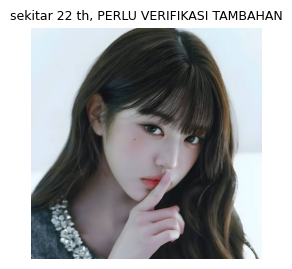

images.jpeg: prediksi mentah 22.27 th (dibulatkan 22 th), L = 18, T = 25, keputusan: PERLU VERIFIKASI TAMBAHAN
  praproses 5.2 ms, inferensi CPU 23.7 ms


In [26]:
# @cell: demo
# Prediksi usia untuk foto yang diunggah, lalu keputusan age-gating.
DEMO_AGE_LIMIT = 18   # batas usia L untuk demo
demo_threshold, _ = recommend_threshold('M1', DEMO_AGE_LIMIT)
if 'm1_cpu_model' not in globals():   # sel efficiency belum dijalankan
    m1_checkpoint = torch.load(get_run_dir('M1', EVAL_SEED) / 'best.pt', map_location='cpu')
    m1_cpu_model = build_model(m1_checkpoint['median_age'], pretrained=False)
    m1_cpu_model.load_state_dict(m1_checkpoint['model'])
    m1_cpu_model.eval()
if IN_COLAB:
    from google.colab import files
    uploaded_files = files.upload()
    for file_name, file_bytes in uploaded_files.items():
        time_start = time.perf_counter()
        with Image.open(io.BytesIO(file_bytes)) as image:
            photo = image.convert('RGB')
        input_tensor = EVAL_TRANSFORM(photo).unsqueeze(0)
        time_preprocessed = time.perf_counter()
        with torch.inference_mode():
            raw_age = float(predict_batch(m1_cpu_model, input_tensor))
        time_predicted = time.perf_counter()
        display_age = int(round(min(max(raw_age, CFG['AGE_RANGE'][0]), CFG['AGE_RANGE'][1])))   # dibatasi ke rentang usia valid
        decision = 'DITERIMA' if raw_age >= demo_threshold else 'PERLU VERIFIKASI TAMBAHAN'
        plt.figure(figsize=(3, 3)); plt.imshow(photo); plt.axis('off')
        plt.title(f'sekitar {display_age} th, {decision}', fontsize=9); plt.show()
        print(f'{file_name}: prediksi mentah {raw_age:.2f} th (dibulatkan {display_age} th), '
              f'L = {DEMO_AGE_LIMIT}, T = {demo_threshold}, keputusan: {decision}')
        print(f'  praproses {1000 * (time_preprocessed - time_start):.1f} ms, '
              f'inferensi CPU {1000 * (time_predicted - time_preprocessed):.1f} ms')
        del file_bytes, photo
else:
    print('Demo unggah hanya tersedia di Colab.')

## Catatan untuk laporan (Bab 3)
- Semua tabel (`results/*.csv`), gambar (`figures/*.png`), dan ringkasan (`results/ringkasan_akhir.json`) tersimpan di Drive dengan akhiran `_val` atau `_test`.
- Laporkan angka data uji hanya dari run setelah `TEST_UNLOCKED = True`. Angka validasi dipakai untuk menjelaskan pemilihan konfigurasi dan T.
- Sertakan juga `manifest/meta.json` (jumlah citra, alasan pengeluaran, pasangan mirip) dan `env_*.json` (perangkat dan versi pustaka).